# Splitting a mesh area into partitions

This notebook explains, step by step, how the yanartas-pillowbox layout splits a security mesh's area into **partitions**, and ports the algorithm (`src/yanartas_pillowbox/partition.py`) so it can be run and inspected here. The port is checked against the original implementation's recorded results (`partition_cases.json`, written by `export_cases.py`).

**Background.** The product is a tamper-detection foil: a flexible PCB folded into a box, both copper layers covered by a dense *mesh* of thin traces. Cutting or drilling through the foil breaks or shorts a trace, which a monitor detects. Each layer's mesh is laid out as a space-filling curve whose traces run in parallel lanes. To keep the traces short and to give the monitor several independent loops, each layer's area is first split into `N` **partitions** of equal area. Each partition gets its own curve and traces, which leave the mesh through its own **port** at the cable junction.

This notebook covers only the split: what the partitions must look like for the curve stage to fill them, and how the partitioner builds them.

In [1]:
from __future__ import annotations  # (as the original modules: annotations not evaluated)

import hashlib
import heapq
import itertools
import json
import math
import secrets
import time
import dataclasses
from collections.abc import Callable, MutableSequence
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import shapely
import shapely.affinity
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path as MplPath
from shapely.geometry import Polygon

DATA = json.loads(Path("partition_cases.json").read_text())
print("cases:", ", ".join(c["name"] for c in DATA["cases"]))
print("recorded with shapely", DATA["shapely"], "numpy", DATA["numpy"],
      "| here: shapely", shapely.__version__, "numpy", np.__version__)

cases: typical, single, six, dumbbell, fold-at-exits, necks
recorded with shapely 2.2.0 numpy 2.5.4 | here: shapely 2.2.0 numpy 2.5.4


## Test cases and plotting conventions

Six small cases, recorded from the original implementation. Every plot below uses the same colours:

| element | drawn as |
|---|---|
| area outline | black line |
| fold between panels (zones) | dashed grey line |
| port (exit cell at the junction) | dark grey square |
| strip (straight lane from a port into the area) | light grey, hatched |
| partition `k` | fill colour `k` (same in every plot) |
| Voronoi cell walls | thin grey lines |
| strip-end cell (*front*) | black star |
| what a step changed | **red outline** |

In [2]:
PALETTE = ["#4E79A7", "#F28E2B", "#59A14F", "#B07AA1", "#76B7B2", "#EDC948", "#9C755F", "#BAB0AC"]
CHANGED = "#D62728"
PORT_C, STRIP_C, FOLD_C, CELL_C = "#333333", "#CFCFCF", "#666666", "#9A9A9A"


def geoms(g):
    return [p for p in shapely.get_parts(g) if not p.is_empty]


def fill(ax, g, **kw):
    """Draw a (multi)polygon, holes included."""
    for p in geoms(g):
        if p.geom_type != "Polygon":
            continue
        rings = [p.exterior, *p.interiors]
        verts, codes = [], []
        for r in rings:
            xy = np.asarray(r.coords)
            verts += xy.tolist()
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
        ax.add_patch(PathPatch(MplPath(verts, codes), **kw))


def case_geom(c):
    i = c["input"]
    return dict(
        area=shapely.from_wkt(i["area"]), zones=[shapely.from_wkt(z) for z in i["zones"]],
        ports=[shapely.from_wkt(p) for p in i["ports"]], inward=tuple(i["inward"]),
        width=i["width"], seed=i["seed"],
    )


def base(ax, g, lanes=None, title=None, folds=True):
    """The area's outline, its folds, ports and strips."""
    fill(ax, g["area"], facecolor="none", edgecolor="black", lw=1.2, zorder=5)
    if folds:
        outline = g["area"].boundary
        for z in g["zones"]:
            inner = z.boundary.intersection(g["area"]).difference(outline.buffer(1e-6))
            for line in geoms(inner):
                if line.length > 1e-6 and line.geom_type in ("LineString", "MultiLineString"):
                    for seg in geoms(line):
                        ax.plot(*np.asarray(seg.coords).T, ls="--", color=FOLD_C, lw=1.2, zorder=6)
    for p in g["ports"]:
        fill(ax, p, facecolor=PORT_C, edgecolor="none", zorder=4)
    for s in lanes or []:
        fill(ax, s, facecolor=STRIP_C, edgecolor="#888888", hatch="///", lw=0.5, zorder=4)
    ax.set_aspect("equal")
    ax.autoscale_view()
    if title:
        ax.set_title(title, fontsize=10)


def owners(ax, cells, owner, alpha=0.75, edge=CELL_C):
    for p, k in zip(cells, owner):
        fill(ax, p, facecolor=PALETTE[k % len(PALETTE)] if k >= 0 else "white", edgecolor=edge,
             lw=0.4, alpha=alpha, zorder=2)


def mark(ax, cells, which, color=CHANGED, lw=1.8):
    for i in which:
        fill(ax, cells[i], facecolor="none", edgecolor=color, lw=lw, zorder=7)


def fronts(ax, cells, front):
    for f in front:
        c = cells[f].centroid
        ax.plot(c.x, c.y, marker="*", color="black", ms=9, zorder=8)


def legend(ax, items, **kw):
    """items: list of (kind, colour, label); kind 'patch', 'line', 'dash', 'star', 'dot', 'edge'."""
    hs = []
    for kind, color, label in items:
        if kind == "patch":
            hs.append(Patch(facecolor=color, edgecolor="none", label=label))
        elif kind == "hatch":
            hs.append(Patch(facecolor=STRIP_C, edgecolor="#888888", hatch="///", label=label))
        elif kind == "edge":
            hs.append(Patch(facecolor="none", edgecolor=color, lw=1.8, label=label))
        elif kind == "line":
            hs.append(Line2D([], [], color=color, lw=1.5, label=label))
        elif kind == "dash":
            hs.append(Line2D([], [], color=color, lw=1.2, ls="--", label=label))
        elif kind == "star":
            hs.append(Line2D([], [], color=color, marker="*", ls="none", ms=9, label=label))
        elif kind == "dot":
            hs.append(Line2D([], [], color=color, marker="o", ls="none", ms=4, label=label))
        elif kind == "hollow":
            hs.append(Line2D([], [], color=color, marker="o", mfc="none", ls="none", ms=4, label=label))
    if kw.get("outside"):
        ax.legend(handles=hs, fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5), framealpha=0.9)
    else:
        ax.legend(handles=hs, fontsize=7, loc=kw.get("loc", "upper right"), framealpha=0.9)


BASE_LEGEND = [("line", "black", "area outline"), ("dash", FOLD_C, "fold"),
               ("patch", PORT_C, "port"), ("hatch", None, "strip")]
CASES = {c["name"]: c for c in DATA["cases"]}
GEOM = {n: case_geom(c) for n, c in CASES.items()}
for c in DATA["cases"]:
    print(f"{c['name']:>14}: {c['note']}")

       typical: a rectangle over two panels, 3 partitions: the usual run, borders bend to the fold
        single: one partition: it is the whole area, nothing to balance
           six: 6 partitions from one row of exits: crowded exits, middle strips longest
      dumbbell: two lobes through a one-cell corridor: no even split exists (an error)
 fold-at-exits: a fold slanting past the exits: the strips' order rearranged, each end in one panel
         necks: an L-shaped area, 4 partitions: necks found and widened, several attempts


## 1. The problem

**Inputs** (one layer):

- `area`: the polygon the mesh must cover (the unfolded box's panels, minus margins).
- `zones`: the panels of the folding pattern. Borders between them are **folds**. A curve may cross a fold, but each crossing costs, so partition borders that follow folds are preferred.
- `ports`: `N` squares in a row along the cable junction, one per partition, each `width` wide. `width` is two trace lanes: a partition's traces run in and back out.
- `inward`: the direction from the junction into the area. `seed`: makes the split repeatable, and different between the two layers.

**Output**: `N` partitions, each a polygon holding its port, its **strip** (see step 3.1) and its share of the area, plus its `reach`: how far in from the port its curve opens.

**Constraints**

1. Equal areas, so the traces (one loop per partition) come out of about equal length (within 3 %).
2. Each partition is one piece and holds its own port and strip; together they cover the area once.
3. **No necks.** A partition must not narrow below about 2 port widths between two wide parts of it. The curve stage fills a partition by joining small cycles; through a neck it can only run in and straight back out, so the cycles beyond cannot join and that region stays **bare** (unprotected). This was the cause of the bare areas this work fixed.
4. Borders keep to folds where they can, and differ between the two layers (so their weak spots don't coincide).

**Why it is hard.** All `N` ports sit side by side in a few millimetres at the junction, while the area spreads over a whole folded box with flaps. Every partition has to squeeze out of that cluster and then fan out into a region of its own. Equal areas push borders around globally, the no-neck rule is local, and the two interact: evening out areas tends to nibble partitions thin, and widening a neck takes area from a neighbour.

The plot below shows one case before (inputs) and after (the recorded output).

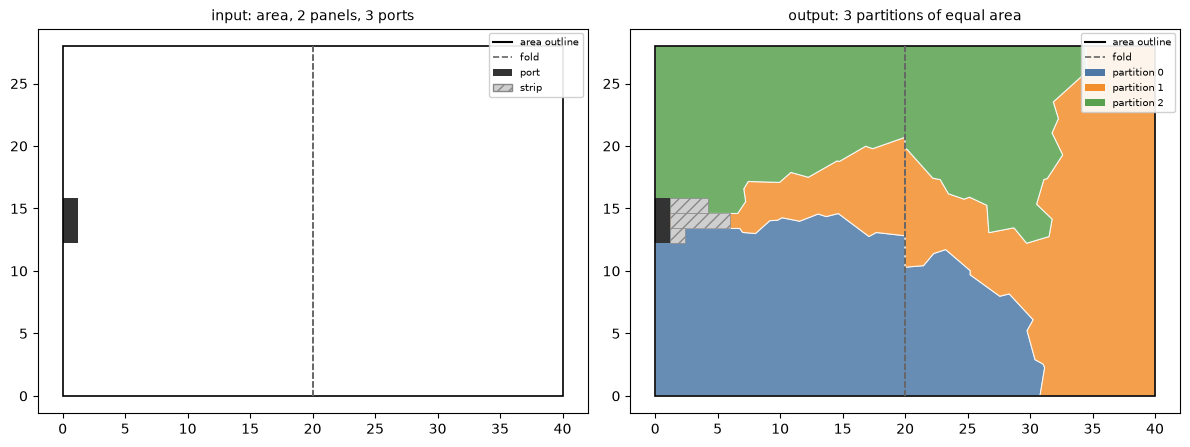

In [3]:
def show_output(ax, name, title=None):
    c, g = CASES[name], GEOM[name]
    for k, o in enumerate(c["output"]):
        fill(ax, shapely.from_wkt(o["area"]), facecolor=PALETTE[k], edgecolor="white", lw=0.8, alpha=0.85, zorder=2)
    base(ax, g, [shapely.from_wkt(w) for w in c["setup"]["lanes"]], title)


fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.6))
g = GEOM["typical"]
base(a, g, title="input: area, 2 panels, 3 ports")
legend(a, BASE_LEGEND)
show_output(b, "typical", "output: 3 partitions of equal area")
legend(b, BASE_LEGEND[:2] + [("patch", PALETTE[k], f"partition {k}") for k in range(3)])
plt.tight_layout()
plt.show()

## 2. Overview

The partitioner works on a **cell graph**: the area is cut into Voronoi cells a few ports across, and a partition is a set of cells. Setup is done once; then a randomized split is attempted up to 6 times and the best attempt is kept.

```
partition(area, zones, ports, inward, width, seed)
│
├─ setup (_Cells.__init__), once
│   3.1  strips            each port's straight lane into the area, staggered lengths
│   3.2  cells             Voronoi cells per panel (Lloyd-relaxed), a cell pinned at each strip end
│   3.3  end boxes         each strip end's cell gets a box in front of the strip all to itself
│   3.4  walls & graphs    shared walls; neighbours through walls ≥ 1 port ("nbrs") or any ("loose")
│   3.5  neck probes       test points + the walls near each (for the no-neck rule)
│
├─ attempt (_Cells.attempt), up to 6 times, each with fresh randomness
│   3.6  cost field        step costs: distance × noise × smooth random field (× 4 across folds)
│   3.7  weighted growth   each cell to the strip end with the cheapest weighted path
│   3.8  hand-on           cells no path reached go to the neighbour beside them
│   3.9  refine            reconnect, smooth borders, even out the areas
│   3.10 widen necks       give a partition the cells that widen its narrowest passage
│   3.11 guarded refine    even out areas again without narrowing anything
│
├─ 3.12 choose            first attempt with no neck and areas within 3 %, else the best
├─ 3.13 pinched           cells beyond a passage too thin for any curve go to the neighbour
└─ 3.14 finish            union each partition's cells + port + strip into a polygon
```

Outside this function (in `pcb._partitioned`), a layer whose curves still leave a region bare is split again from scratch with the seed salted (`seed-1`, `seed-2`, …). Section 5 says more.

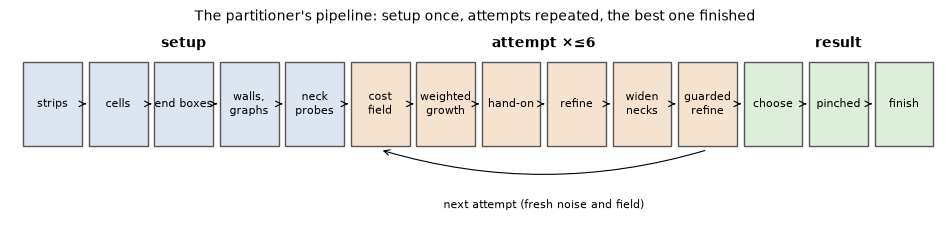

In [4]:
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.axis("off")
steps = [("setup", ["strips", "cells", "end boxes", "walls,\ngraphs", "neck\nprobes"], "#DDE6F0"),
         ("attempt ×≤6", ["cost\nfield", "weighted\ngrowth", "hand-on", "refine", "widen\nnecks", "guarded\nrefine"], "#F6E3CF"),
         ("result", ["choose", "pinched", "finish"], "#DCEFD9")]
x = 0
for group, names, color in steps:
    x0 = x
    for n in names:
        ax.add_patch(plt.Rectangle((x, 0), 0.9, 1, facecolor=color, edgecolor="#555"))
        ax.text(x + 0.45, 0.5, n, ha="center", va="center", fontsize=8)
        if x > 0:
            ax.annotate("", xy=(x, 0.5), xytext=(x - 0.1, 0.5), arrowprops=dict(arrowstyle="->", lw=0.8))
        x += 1
    ax.text((x0 + x - 0.1) / 2, 1.18, group, ha="center", fontsize=10, weight="bold")
ax.annotate("", xy=(5.45, -0.05), xytext=(10.45, -0.05),
            arrowprops=dict(arrowstyle="->", lw=0.8, connectionstyle="arc3,rad=-0.15"))
ax.text(7.95, -0.75, "next attempt (fresh noise and field)", ha="center", fontsize=8)
ax.set_xlim(-0.2, x)
ax.set_ylim(-1.0, 1.4)
ax.set_title("The partitioner's pipeline: setup once, attempts repeated, the best one finished", fontsize=10)
plt.show()

## 3. The port, step by step

The code cells below hold the original functions verbatim (copied from `partition.py` and `rand.py` when this notebook was built), with two changes, called out here:

- The decorator `@checkpoint.step("partition")` is dropped. It only times and checkpoints calls.
- `MeshError` and the RNG `Rand` are defined here instead of imported from the package.

Every name, step and order is the original's, so a cell maps straight back to the source.

### 3.0 Constants, errors and randomness

The randomness must be reproduced bit for bit, or nothing downstream matches. `Rand` is a SHAKE-256 stream keyed from the seed. Each consumer derives its own key under a label (here `"partition"`), so no two parts of the layout share a stream.

In [5]:
LLOYD = 3  # Lloyd iterations of the cells
CELL = 2.5  # the cells this many ports across
STRIP = 1.0  # the outer strips this many ports long (in front of the port)
STAGGER = 1.5  # ... each further in this many ports longer than the one outside it
FOLD = 4.0  # crossing a fold costs this many times as far
NOISE = 0.1  # each step's cost randomized by up to this share
FIELD = 0.5  # ... and varied by up to this share over the area (smoothly)
WAVES = 4  # ... (a sum of this many plane waves)
ITERATIONS = 60  # rounds setting the weights for partitions of equal area
SMOOTH = 4  # passes giving cells to the partition that holds most of their border
ACROSS = 0.25  # ... a neighbour across a fold counting this much
BALANCE = 0.01  # partitions' areas within this share of each other
HOPS = 6  # a partition kept of a piece: looked for this many cells round a cell it gives up
ATTEMPTS = 6  # tries at an even split, with no neck
UNEVEN = 0.03  # ... even: the partitions' areas within this share of each other
LOPSIDED = UNEVEN  # ... but rather one with a neck than one less even than that
NECK = 2.0  # a partition no narrower than this many ports where it can be wider
PART = 3  # ... where it is wider: this many cells, or more
WALL = (0.25, 0.5, 0.75)  # ... tested at these points along each wall between cells
WIDEN = 20  # ... widened at most this many times a partition and zone a round


class MeshError(ValueError):
    """The mesh cannot be laid out (as yanartas_pillowbox.mesh.MeshError)."""


class Uneven(MeshError):
    """No try split the area evenly."""


@dataclass(frozen=True)
class Partition:
    """One partition: what its mesh covers (its cells, and in front of them its port and
    strip, where its stem runs), its port and how far in from the port's outer side its
    curve opens (the strip's end)."""

    area: Polygon
    port: Polygon
    reach: float


def _parts(g: shapely.Geometry) -> list[Polygon]:
    return [p for p in shapely.get_parts(g) if isinstance(p, Polygon) and p.area > 1e-9]


def _one(g: shapely.Geometry, port: Polygon) -> Polygon:
    """The piece reaching the port (the rest, if any, unreachable: dropped)."""
    pieces = _parts(g)
    return max(pieces, key=lambda q: (q.intersects(port.buffer(1e-6)), q.area))

In [6]:
DOMAIN = b"yanartas-pillowbox/rng/v1"
BLOCK = 1024  # bytes of stream drawn at a time


def _frame(*parts: bytes) -> bytes:
    """The parts, each length-prefixed: unambiguous however they split."""
    return b"".join(len(p).to_bytes(4, "big") + p for p in parts)


def derive(key: bytes, label: str) -> bytes:
    """The 256-bit key ``key`` gives the consumer ``label`` (e.g. "layer/F.Cu", "kimesh")."""
    return hashlib.shake_256(_frame(DOMAIN, b"key", key, label.encode())).digest(32)


def key_of(seed: str | int | bytes | None) -> bytes:
    """A seed's 256-bit key: text (as ``Config.mesh_seed``) distilled; a whole number (as
    tests and scripts pass) as its digits, in a domain of its own; a key as it is; none, a
    fresh one from the system's secure source."""
    if seed is None:
        return secrets.token_bytes(32)
    if isinstance(seed, bytes):
        if len(seed) != 32:
            raise ValueError("a key is 32 bytes")
        return seed
    kind = b"int" if isinstance(seed, int) else b"text"
    return hashlib.shake_256(_frame(DOMAIN, b"seed", kind, str(seed).encode())).digest(32)


@dataclasses.dataclass
class Rand:
    """A deterministic, cryptographically secure stream of uniform numbers from a 256-bit
    key (``key``, hex; ``block`` and ``pos`` where in the stream it is: its whole state, so
    checkpoints keep it)."""

    key: str
    block: int = 0
    pos: int = 0

    def __post_init__(self) -> None:
        self._buf = b""
        self._at = -1  # (the block ``_buf`` holds)

    @classmethod
    def of(cls, seed: str | int | bytes | None, label: str) -> Rand:
        """The stream for consumer ``label`` of ``seed``."""
        return cls(derive(key_of(seed), label).hex())

    def child(self, label: str) -> Rand:
        """A stream of its own for consumer ``label`` (from the key, not this stream)."""
        return Rand(self.key_for(label).hex())

    def key_for(self, label: str) -> bytes:
        """The 256-bit key for consumer ``label`` (e.g. one in the Rust core)."""
        return derive(bytes.fromhex(self.key), label)

    def take(self, n: int) -> bytes:
        """The stream's next ``n`` bytes."""
        out = bytearray()
        while len(out) < n:
            if self._at != self.block:
                msg = _frame(
                    DOMAIN, b"stream", bytes.fromhex(self.key), self.block.to_bytes(8, "big")
                )
                self._buf = hashlib.shake_256(msg).digest(BLOCK)
                self._at = self.block
            take = min(n - len(out), BLOCK - self.pos)
            out += self._buf[self.pos : self.pos + take]
            self.pos += take
            if self.pos == BLOCK:
                self.block, self.pos = self.block + 1, 0
        return bytes(out)

    def _words(self, n: int) -> np.ndarray:
        return np.frombuffer(self.take(8 * n), dtype="<u8")

    def random(self, size: int | tuple[int, ...] | None = None) -> Any:
        """Uniform in [0, 1): one float, or an array of ``size`` (53 bits each)."""
        shape = () if size is None else size
        n = int(np.prod(shape))
        x = (self._words(n) >> np.uint64(11)).astype(float) / float(1 << 53)
        return float(x[0]) if size is None else x.reshape(shape)

    def uniform(self, low: Any = 0.0, high: Any = 1.0, size: Any = None) -> Any:
        """Uniform in [low, high) (broadcast against ``size``, as numpy's)."""
        low, high = np.asarray(low, float), np.asarray(high, float)
        if size is None:
            size = np.broadcast(low, high).shape or None
        u = self.random(size)
        out = low + (high - low) * u
        return float(out) if np.ndim(out) == 0 else out

    def below(self, n: int) -> int:
        """Uniform in 0 .. n - 1, without bias (64-bit draws, the uneven top rejected)."""
        if n <= 0:
            raise ValueError("n must be positive")
        limit = (1 << 64) - (1 << 64) % n
        while True:
            w = int.from_bytes(self.take(8), "little")
            if w < limit:
                return w % n

    def shuffle(self, x: MutableSequence[Any]) -> None:
        """In place, uniformly (Fisher-Yates)."""
        for i in range(len(x) - 1, 0, -1):
            j = self.below(i + 1)
            x[i], x[j] = x[j], x[i]

### 3.1 Strips

Each port continues straight into the area as a **strip**, exactly as wide as the port. The partition's traces run along it at full pitch (the *stem*), and its curve opens at the strip's end. The strips lie side by side with nothing between them, so they must have different lengths. Otherwise each partition's opening would face only the strip ends beside it.

The middle strips are the longest: the outer ones are 1 port long and each step inwards adds 1.5 ports. This way every strip's end, and a stretch of its side, faces open area. When a fold runs close to the ports, a strip may end right on the fold, where its curve has no room to open. `strips` then tries the other "rising then falling" orders of lengths until every strip's end square lies inside one panel.

In [7]:
def strips(
    ports: list[Polygon],
    inward: tuple[float, float],
    width: float,
    zones: list[Polygon] | None = None,
) -> list[Polygon]:
    """Each port's strip: from the port's inner side straight on in, as wide; the middle
    ones longest, no two side by side as long. With ``zones``, in the first order (rising
    to the longest and falling off again; the outer ports' shortest first on the first
    port's side) that leaves the square in front of every strip's end (where its curve
    opens) within one zone: off a fold that closes in on the ports, a strip running along it
    would end too near it for its curve to open (its domain keeps half a spacing off)."""
    inv = np.asarray(inward, float) / math.hypot(*inward)
    count = len(ports)
    first = sorted(range(count), key=lambda k: (min(k, count - 1 - k), k))
    orders = [first]
    if zones is not None and count <= 6:
        for perm in itertools.permutations(range(count)):
            depth = [perm.index(k) for k in range(count)]  # (each port's rank)
            top = depth.index(max(depth))
            rises = all(a < b for a, b in itertools.pairwise(depth[: top + 1]))
            falls = all(a > b for a, b in itertools.pairwise(depth[top:]))
            if rises and falls and list(perm) != first:
                orders.append(list(perm))

    def laid(rank: list[int]) -> list[tuple[Polygon, Polygon]]:
        out = []
        for k, port in enumerate(ports):
            depth = width * (STRIP + STAGGER * rank.index(k))
            d = shapely.get_coordinates(port) @ inv
            step = float(d.max() - d.min())
            ahead = shapely.affinity.translate(port, *(inv * step))
            far = shapely.affinity.translate(port, *(inv * (step + depth - width)))
            end = shapely.affinity.translate(port, *(inv * (step + depth)))
            out.append((shapely.union_all([ahead, far]).convex_hull, end))
        return out

    if zones is None:
        return [lane for lane, _ in laid(first)]
    grown = [z.buffer(1e-6) for z in zones]
    for rank in orders:
        lanes = laid(rank)
        if all(any(z.contains(end) for z in grown) for _, end in lanes):
            return [lane for lane, _ in lanes]
    raise MeshError(
        "no room for the mesh's exits beside a fold (move the cable's entry: see Cable entry)"
    )

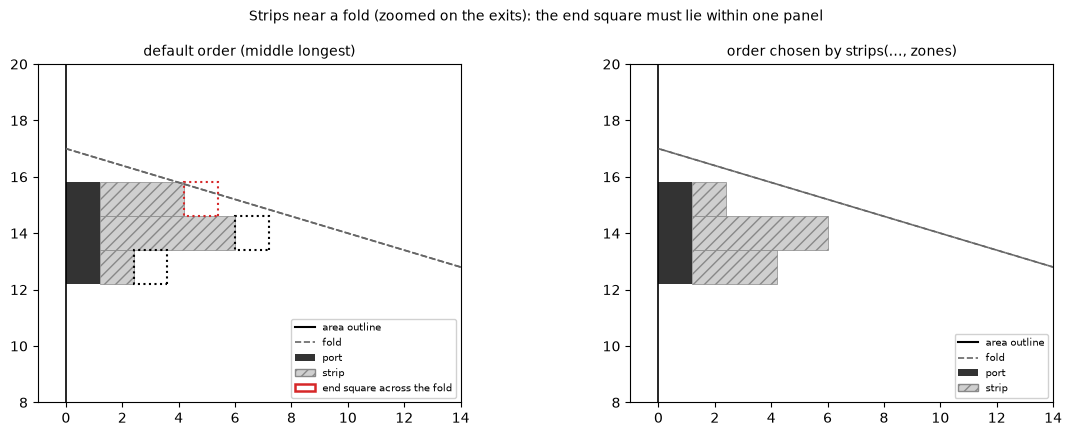

matches the recorded strips: True


In [8]:
g = GEOM["fold-at-exits"]
inv = np.array([1.0, 0.0])
count = len(g["ports"])
first = sorted(range(count), key=lambda k: (min(k, count - 1 - k), k))


def ends_of(rank):
    out = []
    for k, port in enumerate(g["ports"]):
        depth = g["width"] * (STRIP + STAGGER * rank.index(k))
        out.append(shapely.affinity.translate(port, *(inv * (g["width"] + depth))))
    return out


default = strips(g["ports"], g["inward"], g["width"])          # no zones: the first order
chosen = strips(g["ports"], g["inward"], g["width"], g["zones"])  # zones: an order that fits
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, lanes, title, rank in [(axes[0], default, "default order (middle longest)", first),
                               (axes[1], chosen, "order chosen by strips(…, zones)", None)]:
    base(ax, g, lanes, title)
    if rank is not None:
        for e in ends_of(rank):
            bad = not any(z.buffer(1e-6).contains(e) for z in g["zones"])
            fill(ax, e, facecolor="none", edgecolor=CHANGED if bad else "black", lw=1.5, ls=":", zorder=7)
    ax.set_xlim(-1, 14)
    ax.set_ylim(8, 20)
legend(axes[0], BASE_LEGEND + [("edge", CHANGED, "end square across the fold")], loc="lower right")
legend(axes[1], BASE_LEGEND, loc="lower right")
plt.suptitle("Strips near a fold (zoomed on the exits): the end square must lie within one panel", fontsize=10)
plt.tight_layout()
plt.show()
check_lanes = [shapely.from_wkt(w) for w in CASES["fold-at-exits"]["setup"]["lanes"]]
print("matches the recorded strips:", all(a.equals_exact(b, 1e-9) for a, b in zip(chosen, check_lanes)))

### 3.2 Cells

The rest of the area (minus ports and strips) is cut into **Voronoi cells** about 2.5 ports across. Each panel is cut on its own, so no cell straddles a fold. Seeds are drawn uniformly, then moved to their cells' centroids three times (**Lloyd's relaxation**), which makes the cells round and even. One seed is **pinned** a little in front of each strip's end and never moves: its cell is that partition's starting cell, its **front**.

Why cells and not a pixel grid or the exact geometry? Partitions need hundreds of local moves, each with a connectivity check. A cell graph of a few hundred nodes makes those moves cheap, and its granularity (a few ports) matches the scale that matters to the curve.

In [9]:
def cells(
    area: shapely.Geometry,
    zones: list[Polygon],
    size: float,
    rng: Rand,
    pins: list[tuple[float, float]] = (),
) -> tuple[list[Polygon], list[int], list[int]]:
    """The area as Voronoi cells about ``size`` across, each zone's on its own (Lloyd's
    relaxation; a seed at each of ``pins`` stays there): the cells, each one's zone, and
    each pin's cell (-1: none)."""
    out: list[Polygon] = []
    zone: list[int] = []
    pieces = [(zi, p) for zi, z in enumerate(zones) for p in _parts(z.intersection(area))]
    covered = shapely.union_all([z for z in zones]) if zones else Polygon()
    pieces += [(len(zones), p) for p in _parts(shapely.difference(area, covered))]
    held = np.asarray(pins, float).reshape(-1, 2)
    for zi, piece in pieces:
        k = max(1, round(piece.area / (size * size * math.sqrt(3) / 2)))
        x0, y0, x1, y1 = piece.bounds
        shapely.prepare(piece)
        mine = held[shapely.contains_xy(piece, held[:, 0], held[:, 1])]
        pts = np.zeros((0, 2))
        while len(pts) < k:
            q = rng.uniform((x0, y0), (x1, y1), (4 * k, 2))
            pts = np.vstack([pts, q[shapely.contains_xy(piece, q[:, 0], q[:, 1])]])
        pts = pts[:k]
        if len(mine):
            far = np.hypot(*(pts[:, None] - mine[None]).transpose(2, 0, 1)).min(1) > size / 2
            pts = np.vstack([mine, pts[far]])
        box = shapely.box(x0, y0, x1, y1).buffer(size)
        for it in range(LLOYD + 1):
            got = shapely.intersection(_voronoi(pts, box), piece)
            if it == LLOYD:
                break
            pts = shapely.get_coordinates(shapely.centroid(got))
            pts[: len(mine)] = mine
        for c in got:
            for p in _parts(c):
                out.append(p)
                zone.append(zi)
    at = []
    for q in held:
        hit = [i for i, c in enumerate(out) if c.covers(shapely.Point(q))]
        at.append(hit[0] if hit else -1)
    return out, zone, at


def _voronoi(pts: np.ndarray, box: Polygon) -> np.ndarray:
    """Each point's Voronoi cell (within ``box``), in the points' order (shapely's
    ``ordered`` is newer than the browser's shapely)."""
    cells_ = np.asarray(shapely.get_parts(shapely.voronoi_polygons(
        shapely.multipoints(pts), extend_to=box
    )))  # fmt: skip
    at, cell = shapely.STRtree(cells_).query(shapely.points(pts), predicate="intersects")
    out = np.empty(len(pts), dtype=object)
    out[at] = cells_[cell]  # (a point on two cells' wall: either)
    return out

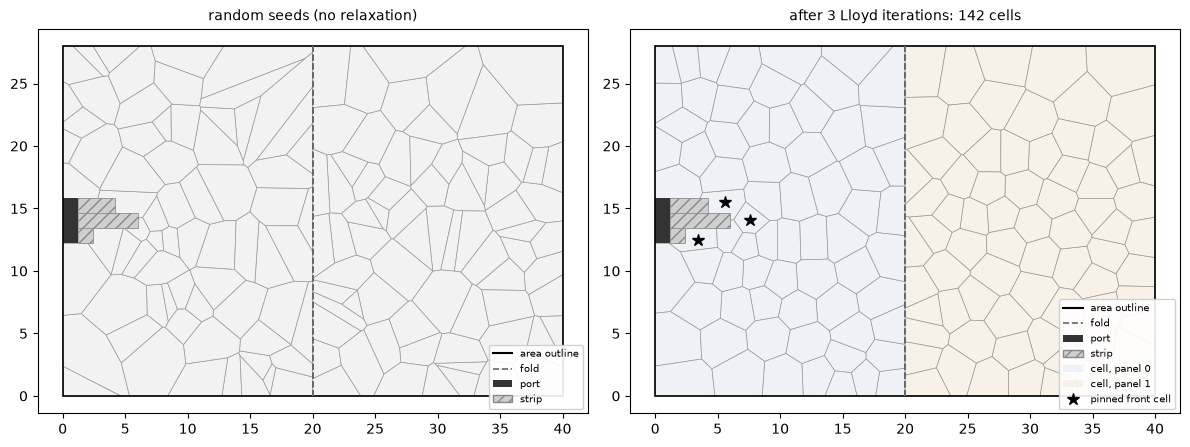

cells match the recording: True | zones: True | fronts: True


In [10]:
g = GEOM["typical"]
rec = CASES["typical"]["setup"]
lanes = strips(g["ports"], g["inward"], g["width"], g["zones"])
inv = np.array(g["inward"]) / math.hypot(*g["inward"])
ends = []
for s in lanes:
    d = shapely.get_coordinates(s) @ inv
    mid = np.asarray(s.centroid.coords[0]) + inv * (float(d.max()) - float(s.centroid.coords[0] @ inv))
    ends.append(tuple(mid + inv * CELL * g["width"] / 2))
rest = shapely.difference(g["area"], shapely.union_all([*g["ports"], *lanes]))

# The same draws with no Lloyd iterations, to show what relaxation does (illustration only)
rng = Rand.of(g["seed"], "partition")
saved, LLOYD = LLOYD, 0
raw, _, _ = cells(rest, g["zones"], CELL * g["width"], rng, ends)
LLOYD = saved
rng = Rand.of(g["seed"], "partition")
polys, zone, front = cells(rest, g["zones"], CELL * g["width"], rng, ends)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, ps, title in [(axes[0], raw, "random seeds (no relaxation)"),
                      (axes[1], polys, f"after {LLOYD} Lloyd iterations: {len(polys)} cells")]:
    zs = zone if ps is polys else [0] * len(ps)
    for p, z in zip(ps, zs):
        fill(ax, p, facecolor=["#EEF2F7", "#F7F1E8"][z % 2] if ps is polys else "#F2F2F2",
             edgecolor=CELL_C, lw=0.5, zorder=2)
    base(ax, g, lanes, title)
fronts(axes[1], polys, front)
legend(axes[1], BASE_LEGEND + [("patch", "#EEF2F7", "cell, panel 0"), ("patch", "#F7F1E8", "cell, panel 1"),
                               ("star", "black", "pinned front cell")], loc="lower right")
legend(axes[0], BASE_LEGEND, loc="lower right")
plt.tight_layout()
plt.show()
want = [shapely.from_wkt(w) for w in rec["voronoi"]["cells"]]
print("cells match the recording:", len(want) == len(polys) and all(a.equals_exact(b, 1e-9) for a, b in zip(polys, want)),
      "| zones:", zone == rec["voronoi"]["zone"], "| fronts:", front == rec["voronoi"]["front"])

### 3.3 End boxes

The square right in front of each strip's end (¾ port deep, a port wide) is where the curve opens, so it must belong to that partition. A plain Voronoi cell might leave part of it to a neighbouring cell. The box is cut out of every other cell and added to the front cell. Cells left empty by this are dropped, and the indices are remapped.

This code lives inline in `_Cells.__init__`; the whole class is defined at the end of the setup (3.5). Here the effect is shown on the cells from 3.2.

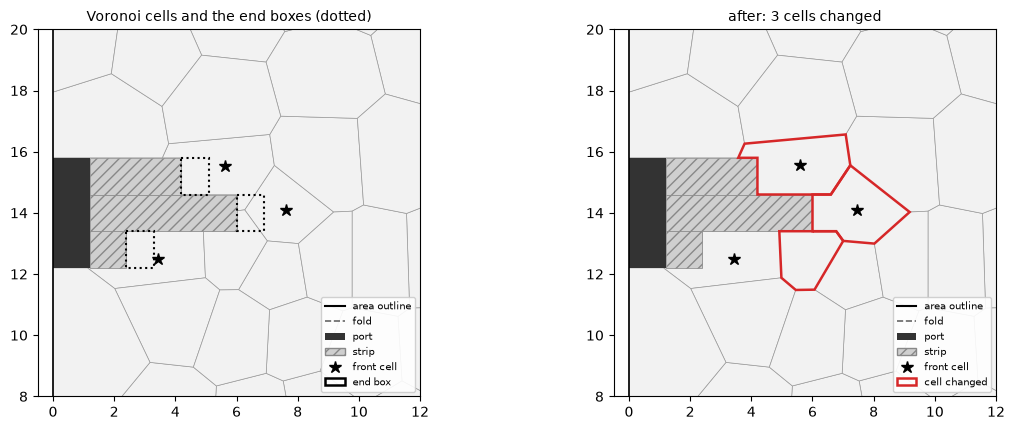

In [11]:
side = np.array([-inv[1], inv[0]]) * g["width"] / 2
boxed = list(polys)
boxes = []
for k, end in enumerate(ends):
    e = np.asarray(end) - inv * CELL * g["width"] / 2
    f = e + inv * 0.75 * g["width"]
    cut = shapely.intersection(Polygon([e - side, e + side, f + side, f - side]), rest)
    boxes.append(cut)
    for i in range(len(boxed)):
        if i != front[k] and boxed[i].intersects(cut):
            boxed[i] = max(_parts(boxed[i].difference(cut)) or [Polygon()], key=lambda q: q.area)
    boxed[front[k]] = _one(shapely.union_all([boxed[front[k]], cut]), boxed[front[k]])
changed = [i for i in range(len(polys)) if not polys[i].equals(boxed[i])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, ps, title in [(axes[0], polys, "Voronoi cells and the end boxes (dotted)"),
                      (axes[1], boxed, f"after: {len(changed)} cells changed")]:
    for p in ps:
        fill(ax, p, facecolor="#F2F2F2", edgecolor=CELL_C, lw=0.5, zorder=2)
    base(ax, g, lanes, title)
    fronts(ax, ps, front)
    ax.set_xlim(-0.5, 12)
    ax.set_ylim(8, 20)
for b in boxes:
    fill(axes[0], b, facecolor="none", edgecolor="black", ls=":", lw=1.5, zorder=8)
mark(axes[1], boxed, changed)
legend(axes[0], BASE_LEGEND + [("star", "black", "front cell"), ("edge", "black", "end box")], loc="lower right")
legend(axes[1], BASE_LEGEND + [("star", "black", "front cell"), ("edge", CHANGED, "cell changed")], loc="lower right")
plt.tight_layout()
plt.show()

### 3.4 Walls and graphs

Two cells are neighbours if they share a **wall**. `_walls` finds every touching pair and their shared border. `_graph` then builds two adjacency lists, each edge weighted by the distance between cell centroids (4× across a fold):

- **`nbrs`** uses only walls at least ~1 port long. All growing and balancing moves use it, so a partition never connects through a pinch point narrower than its traces' run in and back out.
- **`loose`** uses every wall (≥ 0.001). It is used for "beside" questions: handing on cells nothing reached, and neighbourhoods for the neck tests.

`_connected` asks whether partition `p` stays in one piece without a given cell. It searches nearby first (`HOPS` rings), since most answers are local.

In [12]:
def _walls(polys: list[Polygon]) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """The walls between cells: each pair's cells (``a < b``) and their shared border."""
    tree = shapely.STRtree(polys)
    a, b = tree.query(polys, predicate="intersects")
    keep = a < b
    a, b = a[keep], b[keep]
    arr = np.asarray(polys, dtype=object)
    return a, b, shapely.intersection(shapely.boundary(arr[a]), shapely.buffer(arr[b], 1e-6))


def _graph(
    walls: tuple[np.ndarray, np.ndarray, np.ndarray],
    cen: np.ndarray,
    zone: list[int],
    wall: float,
) -> list[list[tuple[int, float]]]:
    """Each cell's neighbours (sharing a border at least ``wall`` long), with the cost of
    the step to it."""
    a, b, shared = walls
    nbrs: list[list[tuple[int, float]]] = [[] for _ in cen]
    for i, j, s in zip(a, b, shapely.length(shared), strict=True):
        if s >= wall:
            step = float(np.hypot(*(cen[i] - cen[j]))) * (FOLD if zone[i] != zone[j] else 1.0)
            nbrs[i].append((int(j), step))
            nbrs[j].append((int(i), step))
    return nbrs


def _connected(
    owner: np.ndarray, nbrs: list[list[tuple[int, float]]], p: int, without: int
) -> bool:
    """Whether partition ``p`` stays of a piece without cell ``without``: its neighbours in
    ``p`` still joined to each other (looked for near it first)."""
    mine = [j for j, _ in nbrs[without] if owner[j] == p]
    if len(mine) <= 1:
        return True
    want = set(mine)
    seen = {mine[0]}
    ring = [mine[0]]
    for _ in range(HOPS):
        nxt = []
        for i in ring:
            for j, _ in nbrs[i]:
                if j != without and j not in seen and owner[j] == p:
                    seen.add(j)
                    nxt.append(j)
        ring = nxt
        if want <= seen:
            return True
    # (not near: all the way round)
    while ring:
        nxt = []
        for i in ring:
            for j, _ in nbrs[i]:
                if j != without and j not in seen and owner[j] == p:
                    seen.add(j)
                    nxt.append(j)
        ring = nxt
        if want <= seen:
            return True
    return False

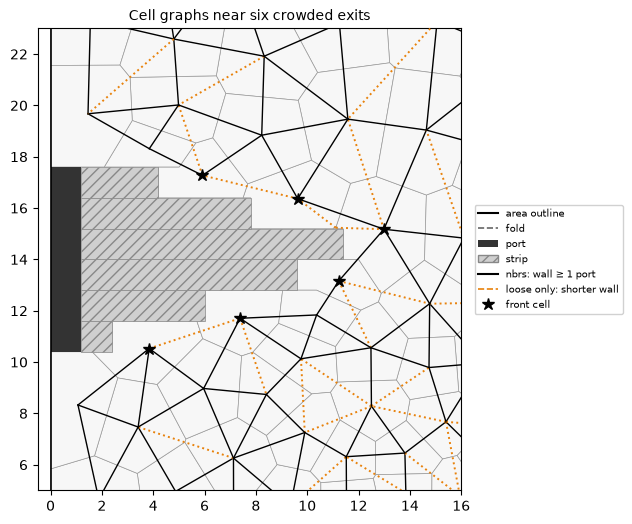

graphs match the recording: True True


In [13]:
c = CASES["six"]
g = GEOM["six"]
cl = [shapely.from_wkt(w) for w in c["setup"]["cells"]["cells"]]
walls = _walls(cl)
cen = shapely.get_coordinates(shapely.centroid(np.asarray(cl, dtype=object)))
zone6 = c["setup"]["cells"]["zone"]
nbrs6 = _graph(walls, cen, zone6, 0.99 * g["width"])
loose6 = _graph(walls, cen, zone6, 1e-3)
fig, ax = plt.subplots(figsize=(9, 6))
for p in cl:
    fill(ax, p, facecolor="#F7F7F7", edgecolor=CELL_C, lw=0.5, zorder=2)
base(ax, g, [shapely.from_wkt(w) for w in c["setup"]["lanes"]], "Cell graphs near six crowded exits")
for i, v in enumerate(loose6):
    strong = {j for j, _ in nbrs6[i]}
    for j, _ in v:
        if i < j:
            style = dict(color="black", lw=1.0) if j in strong else dict(color="#E8820C", lw=1.4, ls=":")
            ax.plot(*cen[[i, j]].T, zorder=6, **style)
fronts(ax, cl, c["setup"]["cells"]["front"])
ax.set_xlim(-0.5, 16)
ax.set_ylim(5, 23)
legend(ax, BASE_LEGEND + [("line", "black", "nbrs: wall ≥ 1 port"), ("dash", "#E8820C", "loose only: shorter wall"),
                          ("star", "black", "front cell")], outside=True)
plt.show()
print("graphs match the recording:", [[j for j, _ in v] for v in nbrs6] == c["setup"]["nbrs"],
      [[j for j, _ in v] for v in loose6] == c["setup"]["loose"])

### 3.5 Neck probes

The no-neck rule needs a cheap test of *"is partition `k` at least 2 ports wide here?"* that can be asked thousands of times while cells move.

**Idea: erosion, sampled at points.** Shrink the partition by 1 port (half the minimum width) on every side. Where the partition is narrower than 2 ports, the shrunken shape breaks apart. Computing that geometrically after every move took seconds per layer. Instead, fixed **probe points** are placed: every cell's centre and three points along every wall (¼, ½, ¾). A probe is **clear** when no border lies within 1 port of it, where a border is the area's outline or any wall whose two cells belong to different partitions.

The geometry never changes, only who owns which cell. So for each probe the walls within reach are found **once** (an R-tree query). After that, clearness is a vectorized lookup: is any nearby wall's pair of cells split between partitions? Probes always near the outline are marked `always` (never clear).

**Wide parts and necks.** A partition's clear cell centres, joined through walls that have at least one clear probe, form groups. Groups of at least `PART` = 3 cells are its **wide parts**. Two wide parts mean they are joined only through something narrower than 2 ports: a **neck**. Two refinements:

- *Natural necks don't count.* If the area itself is narrow there (as if it were one big partition), no split can fix it, so only parts that lie in the same "native" wide region are compared.
- *The exit.* If no wide part lies within two steps of the partition's front cell, the front counts as a part of its own: the partition is cut off from its own exit by a neck.

The test runs twice: on the partition as a whole, and on its piece in each panel (with folds treated as borders), because the curve stage lays out each panel's piece as its own region.

The conceptual picture first, then the real probes.

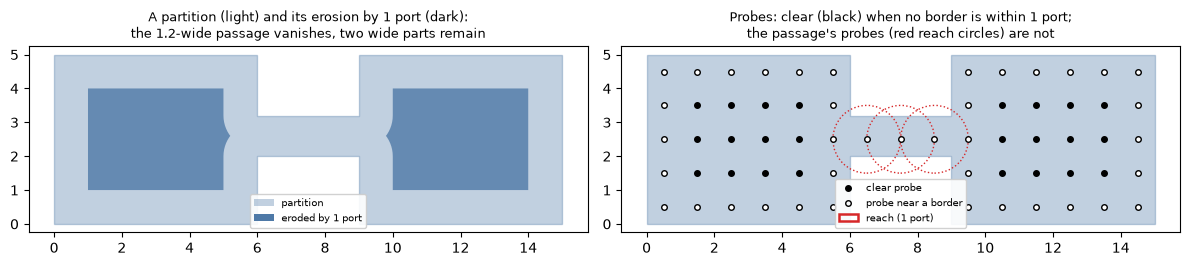

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shape = shapely.union_all([shapely.box(0, 0, 6, 5), shapely.box(6, 2, 9, 3.2), shapely.box(9, 0, 15, 5)])
r = 1.0
eroded = shape.buffer(-r)
ax = axes[0]
fill(ax, shape, facecolor=PALETTE[0], alpha=0.35, edgecolor=PALETTE[0])
fill(ax, eroded, facecolor=PALETTE[0], alpha=0.8, edgecolor="none")
ax.set_title("A partition (light) and its erosion by 1 port (dark):\nthe 1.2-wide passage vanishes, two wide parts remain", fontsize=9)
ax.set_aspect("equal")
ax.autoscale_view()
legend(ax, [("patch", PALETTE[0] + "59", "partition"), ("patch", PALETTE[0], "eroded by 1 port")], loc="lower center")
ax = axes[1]
fill(ax, shape, facecolor=PALETTE[0], alpha=0.35, edgecolor=PALETTE[0])
xs, ys = np.meshgrid(np.arange(0.5, 15, 1.0), np.arange(0.5, 5, 1.0))
pts = shapely.points(xs.ravel(), ys.ravel())
inside = shapely.contains(shape, pts)
clear = shapely.distance(shape.boundary, pts) >= r
for p, i, cl_ in zip(pts, inside, clear):
    if i:
        ax.plot(p.x, p.y, "o", ms=4, color="black" if cl_ else "white", mec="black", zorder=5)
for x0 in (6.5, 7.5, 8.5):
    ax.add_patch(plt.Circle((x0, 2.5), r, fill=False, ls=":", color=CHANGED))
ax.set_title("Probes: clear (black) when no border is within 1 port;\nthe passage's probes (red reach circles) are not", fontsize=9)
ax.set_aspect("equal")
ax.autoscale_view()
legend(ax, [("dot", "black", "clear probe"), ("hollow", "black", "probe near a border"),
            ("edge", CHANGED, "reach (1 port)")], loc="lower center")
plt.tight_layout()
plt.show()

In [15]:
def _components(n: int, a: np.ndarray, b: np.ndarray, node: np.ndarray) -> np.ndarray:
    """Each node's component through the edges ``a``-``b`` (named by its least node; -1:
    not a node): least names passed along the edges, then followed to their own."""
    lab = np.where(node, np.arange(n), -1)
    while True:
        m = np.minimum(lab[a], lab[b])
        new = lab.copy()
        np.minimum.at(new, a, m)
        np.minimum.at(new, b, m)
        on = new >= 0
        while True:  # (each name to its own name's: halving the chains)
            jump = np.where(on, new[np.where(on, new, 0)], -1)
            if (jump == new).all():
                break
            new = jump
        if (new == lab).all():
            return lab
        lab = new


class _Necks:
    """Necks, as where a partition eroded by ``NECK`` ports comes apart, tested at points
    (each cell's centre, and three along each wall between two cells): a point is *clear*
    when no border lies within ``NECK`` ports' half of it, the area's outline or a wall
    between two partitions (zone by zone: or two zones). The walls near each point are
    found once, so whether it is clear is a look at their two cells' partitions. A
    partition's *wide parts* are its cells with clear centres joined through walls with a
    clear point, those of ``PART`` cells or more: two of them are joined only through a
    neck, narrower than a run in and back out, where its curve's graph's cycles join the
    rest at a few cells only, if at all, and leave the part beyond bare. Its exit's cell,
    with no wide part within two steps of it, counts as a part of its own (a neck cuts it
    off from the rest)."""

    def __init__(
        self,
        arr: np.ndarray,
        zone: list[int],
        walls: tuple[np.ndarray, np.ndarray, np.ndarray],
        loose: list[list[tuple[int, float]]],
        front: list[int],
        width: float,
    ) -> None:
        n = len(arr)
        self.n = n
        self.loose = loose
        self.nb = [[j for j, _ in v] for v in loose]
        self.zn = np.asarray(zone)
        self.front = front
        a, b, walls = walls
        keep = shapely.length(walls) >= 1e-3  # (as the loose graph's)
        a, b, walls = a[keep], b[keep], walls[keep]
        self.a, self.b, self.m = a, b, len(a)
        self.wall = {(int(i), int(j)): w for w, (i, j) in enumerate(zip(a, b, strict=True))}
        cen = shapely.centroid(arr)
        off = ~shapely.covers(arr, cen)
        cen[off] = shapely.point_on_surface(arr[off])
        probes = np.concatenate(
            [cen, *(shapely.line_interpolate_point(walls, f, normalized=True) for f in WALL)]
        )
        self.probes = probes
        reach = NECK * width / 2
        outline = shapely.boundary(shapely.union_all(arr, grid_size=1e-6))
        shapely.prepare(outline)
        self.always = shapely.dwithin(outline, probes, reach)
        p, w = shapely.STRtree(walls).query(probes, predicate="dwithin", distance=reach)
        order = np.argsort(p, kind="stable")
        self.pp, self.pa, self.pb = p[order], a[w[order]], b[w[order]]
        self.at = np.searchsorted(self.pp, np.arange(len(probes) + 1))
        self.local: dict[int, tuple] = {}
        self.natives: dict[bool, np.ndarray] = {}
        self.last: tuple = (None, None)

    def clear(self, owner: np.ndarray, zonal: bool) -> np.ndarray:
        """Whether each point is clear."""
        bad = owner[self.pa] != owner[self.pb]
        if zonal:
            bad |= self.zn[self.pa] != self.zn[self.pb]
        out = ~self.always
        out[self.pp[bad]] = False
        return out

    def _wall_clear(self, ok: np.ndarray) -> np.ndarray:
        n, m = self.n, self.m
        return ok[n:].reshape(len(WALL), m).any(0)

    def _labels(self, owner: np.ndarray, zonal: bool) -> np.ndarray:
        """Each cell's group (-1: no clear centre): cells of a partition with clear centres
        joined through walls with a clear point (``zonal``: walls between zones as borders),
        named by a cell of theirs."""
        key = (owner.tobytes(), zonal)
        if self.last[0] == key:
            return self.last[1]
        ok = self.clear(owner, zonal)
        node = ok[: self.n]
        edge = self._wall_clear(ok) & node[self.a] & node[self.b]
        lab = _components(self.n, self.a[edge], self.b[edge], node)
        self.last = (key, lab)
        return lab

    def _native(self, zonal: bool) -> np.ndarray:
        """Each cell's group as if the area were one partition (-1: no clear centre): where
        the area itself is narrow, by its outline or between folds."""
        if zonal not in self.natives:
            self.natives[zonal] = self._labels(np.zeros(self.n, int), zonal)
        return self.natives[zonal]

    def parts(self, owner: np.ndarray, k: int, z: int | None) -> list[list[int]]:
        """Partition ``k``'s wide parts (in zone ``z``; None: all) that a neck parts where
        the area itself is wide, the largest first: of the area's wide stretch where the
        second largest is largest."""
        native = self._native(z is not None)
        lab = self._labels(owner, z is not None)
        mine = (owner == k) & (lab >= 0)
        if z is not None:
            mine &= self.zn == z
        cells = np.nonzero(mine)[0]
        names, which = np.unique(lab[cells], return_inverse=True)
        by: dict[int, list[list[int]]] = {}
        for g in range(len(names)):
            group = cells[which == g].tolist()
            if len(group) >= PART:
                by.setdefault(int(native[group[0]]), []).append(group)
        for gs in by.values():
            gs.sort(key=len, reverse=True)
        groups = max(by.values(), key=lambda gs: len(gs[1]) if len(gs) > 1 else 0, default=[])
        f = self.front[k] if k < len(self.front) else None
        if f is not None and by and (z is None or self.zn[f] == z) and owner[f] == k:
            # (within two steps: the cells beside the exit's touch the strips' ends beside)
            near = {f, *self.nb[f]}
            near |= {j for c in list(near) for j in self.nb[c]}
            if not any(near.intersection(g) for gs in by.values() for g in gs):
                main = max((g for gs in by.values() for g in gs), key=len)
                groups = [main, [f]]
        return groups

    def left(self, owner: np.ndarray) -> int:
        """How many partitions, as a whole or in a zone, have necks."""
        return sum(
            len(self.parts(owner, k, z)) > 1
            for k in range(int(owner.max()) + 1)
            for z in [None, *sorted(set(self.zn[owner == k].tolist()))]
        )

    def narrow(self, owner: np.ndarray, cells: list[int], z: int | None) -> list[int]:
        """The cells whose walls with ``cells`` (and those between them) keep a point
        there from being clear: of other partitions, nearest first."""
        k = int(owner[cells[0]])
        pts = list(cells)
        for i, j in itertools.pairwise(cells):
            w = self.wall.get((min(i, j), max(i, j)))
            if w is not None:
                pts += [self.n + s * self.m + w for s in range(len(WALL))]
        out: dict[int, None] = {}
        for p in pts:
            for e in range(self.at[p], self.at[p + 1]):
                x, y = int(self.pa[e]), int(self.pb[e])
                if owner[x] == owner[y] or self.zn[x] != self.zn[y]:
                    continue  # (no border there, or a fold's: as it is)
                for c in (x, y):
                    if owner[c] != k and (z is None or self.zn[c] == z):
                        out[c] = None
        return list(out)

    def spares(self, owner: np.ndarray, i: int) -> bool:
        """Whether cell ``i`` can leave its partition without narrowing it: round it (three
        steps through walls, in its zone), its partition's cells with clear centres, joined
        through walls with a clear point, come apart into no more groups without it than
        with it."""
        if i not in self.local:
            z = self.zn[i]
            ring, seen = [i], {i}
            for _ in range(3):
                ring = [j for c in ring for j in self.nb[c] if j not in seen and self.zn[j] == z]
                seen.update(ring)
            cells = np.array(sorted(seen))
            ws = np.array(
                [w for c in cells for j in self.nb[c] if c < j and j in seen
                 for w in [self.wall[(c, j)]]],
                int,
            )  # fmt: skip
            pts = np.concatenate([cells, *(self.n + s * self.m + ws for s in range(len(WALL)))])
            ent = np.concatenate([np.arange(self.at[p], self.at[p + 1]) for p in pts])
            slot = np.repeat(np.arange(len(pts)), self.at[pts + 1] - self.at[pts])
            pa, pb = self.pa[ent], self.pb[ent]
            cross = self.zn[pa] != self.zn[pb]
            self.local[i] = (cells, ws, len(pts), slot, pa, pb, cross, ~self.always[pts])
        cells, ws, npts, slot, pa, pb, cross, free = self.local[i]
        m = owner[i]
        oa, ob = owner[pa], owner[pb]

        def groups(without: bool) -> int:
            if without:
                xa, xb = np.where(pa == i, -1, oa), np.where(pb == i, -1, ob)
            else:
                xa, xb = oa, ob
            bad = (xa != xb) | cross
            ok = free & (np.bincount(slot[bad], minlength=npts) == 0)
            mine = owner[cells] == m
            if without:
                mine &= cells != i
            node = set(cells[ok[: len(cells)] & mine].tolist())
            wok = ok[len(cells) :].reshape(len(WALL), len(ws)).any(0)
            adj: dict[int, list[int]] = {}
            for w in ws[wok].tolist():
                x, y = int(self.a[w]), int(self.b[w])
                if x in node and y in node:
                    adj.setdefault(x, []).append(y)
                    adj.setdefault(y, []).append(x)
            n = 0
            while node:
                todo = [node.pop()]
                n += 1
                while todo:
                    c = todo.pop()
                    for j in adj.get(c, ()):
                        if j in node:
                            node.discard(j)
                            todo.append(j)
            return n

        return groups(True) <= groups(False)

`_Cells` ties the setup together (steps 3.1–3.5 in its `__init__`) and holds the per-attempt pipeline (`attempt`, steps 3.6–3.11) and the finishing (`finished`, steps 3.13–3.14). Those steps are explained below.

In [16]:
class _Cells:
    """A layer's area in cells, with its strips and their ends' cells, the cells' graphs
    and necks: set up once for all attempts at a split."""

    def __init__(
        self,
        area: shapely.Geometry,
        zones: list[Polygon],
        ports: list[Polygon],
        inward: tuple[float, float],
        width: float,
        rng: Rand,
    ) -> None:
        count = len(ports)
        self.inv = inv = np.asarray(inward, float) / math.hypot(*inward)
        self.ports, self.width = ports, width
        self.lanes = lanes = strips(ports, inward, width, zones)
        # (a cell pinned in front of each strip's end, its own: where its curve opens)
        ends = []
        for s in lanes:
            d = shapely.get_coordinates(s) @ inv
            mid = np.asarray(s.centroid.coords[0]) + inv * (
                float(d.max()) - float(s.centroid.coords[0] @ inv)
            )
            ends.append(tuple(mid + inv * CELL * width / 2))
        rest = shapely.difference(area, shapely.union_all([*ports, *lanes]))
        polys, zone, front = cells(rest, zones, CELL * width, rng, ends)
        if len(polys) < 2 * count or min(front) < 0 or len(set(front)) < count:
            raise MeshError("no room for the mesh's partitions")
        # (and the strip's end all its own: a box over it, out of the cells beside)
        side = np.array([-inv[1], inv[0]]) * width / 2
        for k, end in enumerate(ends):
            e = np.asarray(end) - inv * CELL * width / 2  # (the strip's end's middle)
            f = e + inv * 0.75 * width
            cut = shapely.intersection(Polygon([e - side, e + side, f + side, f - side]), rest)
            for i in range(len(polys)):
                if i != front[k] and polys[i].intersects(cut):
                    polys[i] = max(
                        _parts(polys[i].difference(cut)) or [Polygon()], key=lambda q: q.area
                    )
            polys[front[k]] = _one(shapely.union_all([polys[front[k]], cut]), polys[front[k]])
        gone = {i for i, q in enumerate(polys) if q.is_empty or q.area < 1e-9}
        if gone:
            keep = [i for i in range(len(polys)) if i not in gone]
            remap = {old: new for new, old in enumerate(keep)}
            polys = [polys[i] for i in keep]
            zone = [zone[i] for i in keep]
            front = [remap[i] for i in front]
        self.zone, self.front = zone, front
        self.arr = arr = np.asarray(polys, dtype=object)
        self.cen = shapely.get_coordinates(shapely.centroid(arr))
        walls = _walls(polys)
        self.nbrs = _graph(walls, self.cen, zone, 0.99 * width)
        # (cells no path through a wide enough wall reaches: given to the partition beside)
        self.loose = _graph(walls, self.cen, zone, 1e-3)
        self.area = shapely.area(arr)
        self.held = np.array([p.area + s.area for p, s in zip(ports, lanes, strict=True)])
        total = float(self.area.sum() + self.held.sum())
        self.want = total / count - self.held
        self.necks = _Necks(arr, zone, walls, self.loose, front, width)

    def attempt(self, rng: Rand) -> tuple[np.ndarray, int]:
        """A split (each cell's partition) and how many necks it has left."""
        nbrs, loose, zone, front = self.nbrs, self.loose, self.zone, self.front
        noise = 1.0 + NOISE * rng.random(len(self.arr))
        field = _field(self.cen, rng)
        cost = [
            [(j, step * noise[j] * (field[i] + field[j]) / 2) for j, step in v]
            for i, v in enumerate(nbrs)
        ]
        owner = _weighted(cost, self.area, [[i] for i in front], self.want)
        for _ in range(len(owner)):
            lost = np.nonzero(owner < 0)[0]
            if not len(lost):
                break
            for i in lost:
                near = [owner[j] for j, _ in loose[i] if owner[j] >= 0]
                if near:
                    owner[i] = max(set(near), key=near.count)
        owner[owner < 0] = 0
        owner = _refine(owner, nbrs, zone, self.area, self.want, front)
        # (necks widened, then the areas evened out again without narrowing any)
        owner = _widened(owner, self.necks, nbrs, set(front))
        owner = _refine(owner, nbrs, zone, self.area, self.want, front, self.necks.spares)
        return owner, self.necks.left(owner)

    def finished(self, owner: np.ndarray) -> list[Partition]:
        """The partitions of a split, what lies past a passage too narrow for any curve
        given to the neighbours."""
        owner = _pinched(owner, self.arr, self.zone, self.loose, self.front, self.width)
        out = []
        for k, (port, lane) in enumerate(zip(self.ports, self.lanes, strict=True)):
            g = shapely.union_all([*self.arr[owner == k], port, lane], grid_size=1e-6)
            d = shapely.get_coordinates(lane) @ self.inv
            e = shapely.get_coordinates(port) @ self.inv
            out.append(Partition(_one(g, port), port, float(d.max() - e.min())))
        return out

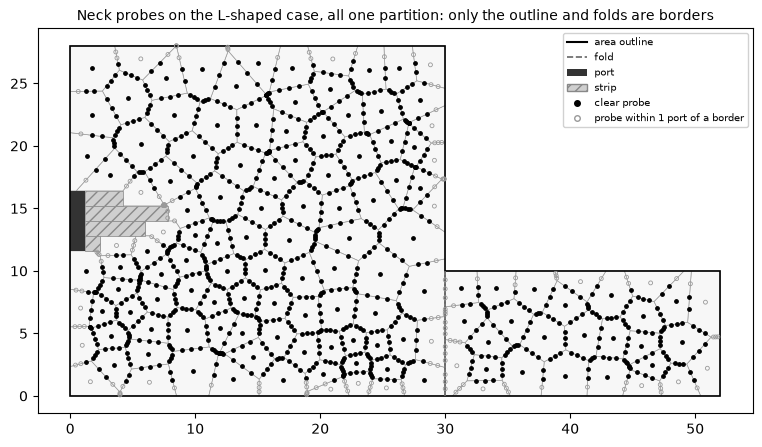

135 cells, 350 walls, 1185 probes; probes and their always-flags match the recording: True True


In [17]:
def setup(name):
    g = GEOM[name]
    rng = Rand.of(g["seed"], "partition")
    return _Cells(g["area"], g["zones"], g["ports"], g["inward"], g["width"], rng), rng


cut, _ = setup("necks")
c, g = CASES["necks"], GEOM["necks"]
probes = shapely.get_coordinates(cut.necks.probes)
ok = cut.necks.clear(np.zeros(cut.necks.n, int), True)  # one partition: only outline and folds
fig, ax = plt.subplots(figsize=(11, 5))
for p in cut.arr:
    fill(ax, p, facecolor="#F7F7F7", edgecolor=CELL_C, lw=0.5, zorder=2)
base(ax, g, cut.lanes, "Neck probes on the L-shaped case, all one partition: only the outline and folds are borders")
ax.scatter(*probes[ok].T, s=6, color="black", zorder=6)
ax.scatter(*probes[~ok].T, s=8, facecolors="none", edgecolors="#999999", lw=0.6, zorder=6)
legend(ax, BASE_LEGEND + [("dot", "black", "clear probe"), ("hollow", "#999999", "probe within 1 port of a border")])
plt.show()
rec = c["setup"]
print(f"{cut.necks.n} cells, {cut.necks.m} walls, {len(probes)} probes;",
      "probes and their always-flags match the recording:",
      np.allclose(probes, rec["probes"]["xy"], atol=1e-9), list(cut.necks.always) == rec["probes"]["always"])

### 3.6 Cost field

An attempt starts by drawing step costs for the cell graph. Each step costs the centroid distance (×4 across a fold), times per-cell **noise** (up to +10 %), times a smooth random **field**: a sum of 4 plane waves, varying ±50 % over the area. The field bends borders consistently over long distances, so the two layers' borders differ in shape and not just in jitter. Each attempt draws new noise and a new field, so the attempts differ.

In [18]:
def _field(cen: np.ndarray, rng: Rand) -> np.ndarray:
    """A smooth random cost over the cells (a few plane waves, about as long as the area
    is wide): the partitions' borders bent one way on one layer, another on the other."""
    span = float(np.ptp(cen, axis=0).max()) or 1.0
    out = np.zeros(len(cen))
    for _ in range(WAVES):
        angle = rng.uniform(0, math.tau)
        k = math.tau / (span * rng.uniform(0.3, 1.0))
        out += np.cos(
            cen @ np.array([math.cos(angle), math.sin(angle)]) * k + rng.uniform(0, math.tau)
        )
    return 1.0 + FIELD * out / WAVES

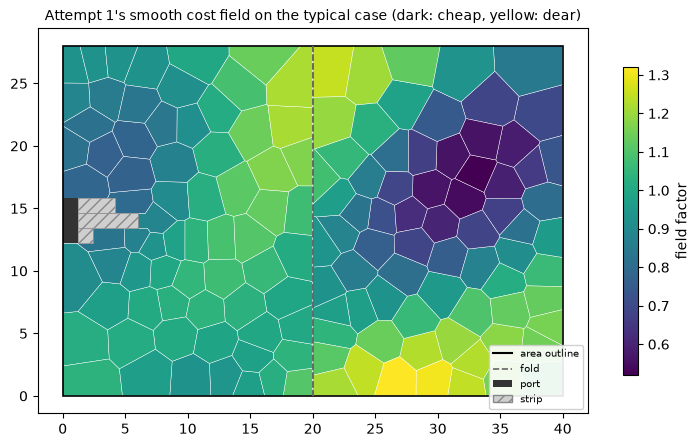

In [19]:
cut, rng = setup("typical")
g = GEOM["typical"]
noise = 1.0 + NOISE * rng.random(len(cut.arr))
field = _field(cut.cen, rng)
fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.get_cmap("viridis")
lo, hi = field.min(), field.max()
for p, f in zip(cut.arr, field):
    fill(ax, p, facecolor=cmap((f - lo) / (hi - lo)), edgecolor="white", lw=0.3, zorder=2)
base(ax, g, cut.lanes, "Attempt 1's smooth cost field on the typical case (dark: cheap, yellow: dear)")
plt.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(lo, hi), cmap=cmap), ax=ax, shrink=0.8, label="field factor")
legend(ax, BASE_LEGEND, loc="lower right")
plt.show()

### 3.7 Weighted growth

Every cell goes to the strip end whose **weighted shortest path** reaches it most cheaply. This is an additively weighted Voronoi diagram on the graph: one multi-source Dijkstra in which partition `k` starts at distance `-w[k]`. Each partition is then the tree of its source's shortest paths, so it is automatically one piece. The weights are adjusted over up to 60 rounds, raising those of partitions below their share, and the most even round is kept. Sources cannot be taken over by a neighbour's paths.

**Why it rarely balances on its own.** All sources sit together at the junction. A small weight change can hand a whole lobe of the area, behind one or two gate cells near the exits, from one partition to another. Areas jump instead of varying smoothly, so the iteration oscillates. The recorded attempts show how far off the weighted result typically is (the table below). Step 3.9 does most of the evening out.

In [20]:
def _weighted(
    cost: list[list[tuple[int, float]]],
    area: np.ndarray,
    sources: list[list[int]],
    want: np.ndarray,
) -> np.ndarray:
    """Each cell to the source its cheapest path starts from, each source's start weighted
    (an additively weighted Voronoi diagram over the cells, from the strips' ends): each
    partition the tree of its source's paths, so of a piece; the weights set so that each
    gets about ``want`` of the area (cells no path reaches: -1)."""
    count = len(sources)
    held = {i for cs in sources for i in cs}  # (each source its own partition's)
    w = np.zeros(count)
    best, best_err = None, math.inf
    step = None
    for _ in range(ITERATIONS):
        owner = np.full(len(area), -1)
        dist = np.full(len(area), np.inf)
        heap = []
        for k, cs in enumerate(sources):
            for i in cs:
                if -w[k] < dist[i]:
                    dist[i] = -w[k]
                    owner[i] = k
                    heap.append((-w[k], i, k))
        heapq.heapify(heap)
        while heap:
            d, i, k = heapq.heappop(heap)
            if d > dist[i] or owner[i] != k:
                continue
            for j, c in cost[i]:
                if d + c < dist[j] and j not in held:
                    dist[j] = d + c
                    owner[j] = k
                    heapq.heappush(heap, (d + c, j, k))
        have = np.bincount(owner[owner >= 0], area[owner >= 0], count)
        err = have / want - 1
        if np.abs(err).max() < best_err:
            best, best_err = owner.copy(), float(np.abs(err).max())
        if best_err < BALANCE / 2:
            break
        if step is None:  # (about a tenth of how far the cells lie from their sources)
            step = 0.1 * float(np.median(dist[np.isfinite(dist)] + w[owner[np.isfinite(dist)]]))
        w -= np.clip(err, -1, 1) * step
        w -= w.mean()
        step *= 0.93
    assert best is not None
    return best

In [21]:
rows = []
for name, c in CASES.items():
    want = np.array(c["setup"]["want"])
    area = np.array(c["setup"]["area"])
    for i, a in enumerate(c["attempts"]):
        o = np.array(a["weighted"])
        have = np.bincount(o[o >= 0], area[o >= 0], len(want))
        rows.append((name, i, np.abs(have / want - 1).max()))
print("worst partition's area off its share after weighted growth (per attempt):")
for name in CASES:
    print(f"  {name:>14}: " + "  ".join(f"{e:5.0%}" for n, i, e in rows if n == name))

worst partition's area off its share after weighted growth (per attempt):
         typical:   33%    36%
          single:    0%
             six:   93%    93%    85%    93%    93%    93%
        dumbbell:   74%    72%    69%    74%    71%    74%
   fold-at-exits:   12%
           necks:   24%    24%    41%    20%    37%    30%


### 3.8 Hand-on, and the attempt itself

Some cells have no path through port-wide walls from any source (for example a cell reachable only through a short wall); `_weighted` leaves them at `-1`. They are handed, repeatedly, to the partition most common among their `loose` neighbours.

The functions `attempt_stages` and `finish_stages` below are **the port's only addition**. They run the same statements as `_Cells.attempt` and `partition`, but also return every intermediate so that it can be plotted and checked. The faithful `_Cells.attempt` and `partition` (above and in 3.12) are verified separately, end to end, in section 4.

In [22]:
def attempt_stages(cut, rng):
    """_Cells.attempt's statements, its intermediates recorded."""
    nbrs, loose, zone, front = cut.nbrs, cut.loose, cut.zone, cut.front
    noise = 1.0 + NOISE * rng.random(len(cut.arr))
    field = _field(cut.cen, rng)
    cost = [[(j, step * noise[j] * (field[i] + field[j]) / 2) for j, step in v] for i, v in enumerate(nbrs)]
    out = {}
    owner = _weighted(cost, cut.area, [[i] for i in front], cut.want)
    out["weighted"] = owner.copy()
    for _ in range(len(owner)):
        lost = np.nonzero(owner < 0)[0]
        if not len(lost):
            break
        for i in lost:
            near = [owner[j] for j, _ in loose[i] if owner[j] >= 0]
            if near:
                owner[i] = max(set(near), key=near.count)
    owner[owner < 0] = 0
    out["grown"] = owner.copy()
    owner = _refine(owner, nbrs, zone, cut.area, cut.want, front)
    out["refined"] = owner
    owner = _widened(owner, cut.necks, nbrs, set(front))
    out["widened"] = owner
    owner = _refine(owner, nbrs, zone, cut.area, cut.want, front, cut.necks.spares)
    out["balanced"] = owner
    out["necks"] = cut.necks.left(owner)
    have = np.bincount(owner, cut.area, len(front)) + cut.held
    out["off"] = float((have.max() - have.min()) / have.max())
    return out


def run_attempts(name):
    cut, rng = setup(name)
    return cut, [attempt_stages(cut, rng) for _ in range(len(CASES[name]["attempts"]))]

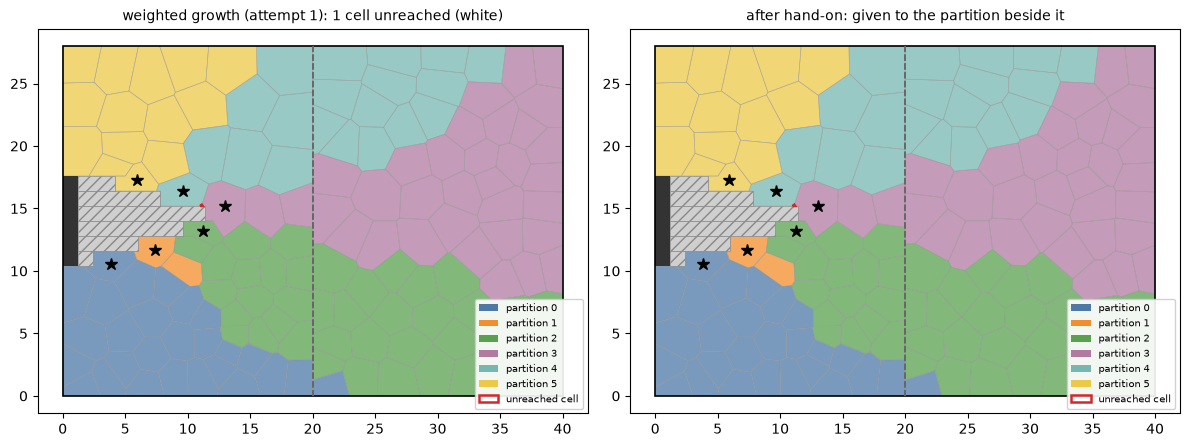

In [23]:
# (attempt 1's first steps by hand: the later ones are defined in the next sections)
cut, rng = setup("six")
g, c = GEOM["six"], CASES["six"]
noise = 1.0 + NOISE * rng.random(len(cut.arr))
field = _field(cut.cen, rng)
cost = [[(j, step * noise[j] * (field[i] + field[j]) / 2) for j, step in v] for i, v in enumerate(cut.nbrs)]
a = {"weighted": _weighted(cost, cut.area, [[i] for i in cut.front], cut.want)}
grown = a["weighted"].copy()
for _ in range(len(grown)):
    lost_ = np.nonzero(grown < 0)[0]
    if not len(lost_):
        break
    for i in lost_:
        near = [grown[j] for j, _ in cut.loose[i] if grown[j] >= 0]
        if near:
            grown[i] = max(set(near), key=near.count)
grown[grown < 0] = 0
a["grown"] = grown
lost = np.nonzero(a["weighted"] < 0)[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
owners(axes[0], cut.arr, a["weighted"])
mark(axes[0], cut.arr, lost)
base(axes[0], g, cut.lanes, f"weighted growth (attempt 1): {len(lost)} cell unreached (white)")
owners(axes[1], cut.arr, a["grown"])
mark(axes[1], cut.arr, lost)
base(axes[1], g, cut.lanes, "after hand-on: given to the partition beside it")
for ax in axes:
    fronts(ax, cut.arr, cut.front)
    legend(ax, [("patch", PALETTE[k], f"partition {k}") for k in range(6)] + [("edge", CHANGED, "unreached cell")], loc="lower right")
plt.tight_layout()
plt.show()

### 3.9 Refine

`_refine` has three passes:

1. **Reconnect.** Any piece of a partition not connected (through `nbrs`) to its front goes to the neighbour that borders it most.
2. **Smooth** (`SMOOTH` passes). A cell moves to the partition holding more than twice as much of its border as its own does. Neighbours across a fold count only ¼, so borders settle onto folds.
3. **Balance.** Repeatedly take the most uneven pair of neighbouring partitions and move border cells from the bigger to the smaller, the cells most surrounded by the smaller one first, until all areas are within `BALANCE` = 1 %. A cell may move only if its old partition stays connected (`_connected`), and, when a `guard` is given (step 3.11), only if the guard allows it. A pair that can't trade is blocked.

Front cells never move.

In [24]:
def _refine(
    owner: np.ndarray,
    nbrs: list[list[tuple[int, float]]],
    zone: list[int],
    area: np.ndarray,
    target: np.ndarray,
    fronts: list[int],
    guard: Callable[[np.ndarray, int], bool] | None = None,
) -> np.ndarray:
    """Each partition of a piece with the cell in front of its strip (cut off pieces to the
    neighbour they border most), its borders smoothed (a cell to the partition holding most of its
    border, a neighbour across a fold counting little) and the areas evened out (cells
    passed on between neighbours, the most uneven pair first), each kept of a piece."""
    owner = owner.copy()
    count = len(target)
    fixed = np.zeros(len(owner), bool)
    fixed[fronts] = True
    src = np.repeat(np.arange(len(owner)), [len(v) for v in nbrs])
    dst = np.array([j for v in nbrs for j, _ in v], int)
    zn = np.asarray(zone)
    weight = np.where(zn[src] == zn[dst], 1.0, ACROSS)

    def votes() -> np.ndarray:
        v = np.bincount(src * count + owner[dst], weight, len(owner) * count)
        return v.reshape(len(owner), count)

    def move(i: int, q: int) -> bool:
        p = int(owner[i])
        if fixed[i] or not _connected(owner, nbrs, p, i):
            return False
        if guard is not None and not guard(owner, i):
            return False
        owner[i] = q
        return True

    for k in range(count):  # (pieces cut off from the strip: to the neighbour most beside)
        seen = {fronts[k]}
        stack = list(seen)
        while stack:
            i = stack.pop()
            for j, _ in nbrs[i]:
                if j not in seen and owner[j] == k:
                    seen.add(j)
                    stack.append(j)
        lost = [i for i in np.nonzero(owner == k)[0] if i not in seen]
        while lost:
            v = votes()
            v[:, k] = 0.0
            rest = []
            for i in lost:
                if v[i].max() > 0:
                    owner[i] = int(np.argmax(v[i]))
                else:
                    rest.append(i)
            if len(rest) == len(lost):
                break
            lost = rest
    for _ in range(SMOOTH):
        v = votes()
        best = np.argmax(v, axis=1)
        mine = v[np.arange(len(owner)), owner]
        cand = np.nonzero((best != owner) & (v.max(1) > 2 * mine) & ~fixed)[0]
        if not sum(move(int(i), int(best[i])) for i in cand):
            break
    blocked: set[tuple[int, int]] = set()
    mean = float(area.mean())
    for _ in range(len(owner)):
        over = np.bincount(owner, area, count) - target
        edge = owner[src] != owner[dst]
        pairs = {(int(a), int(b)) for a, b in zip(owner[src[edge]], owner[dst[edge]], strict=True)}
        pairs = [pq for pq in pairs if pq not in blocked and over[pq[0]] - over[pq[1]] > mean]
        if not pairs or max(over) < BALANCE * float(target.mean()) / 2:
            break
        p, q = max(pairs, key=lambda pq: over[pq[0]] - over[pq[1]])
        need = (over[p] - over[q]) / 2
        v = votes()
        cells_ = np.unique(src[edge & (owner[src] == p) & (owner[dst] == q)])
        cells_ = cells_[np.argsort(-v[cells_, q])]  # (most into q first)
        moved = 0.0
        for i in cells_:
            if moved >= need:
                break
            if move(int(i), q):
                moved += area[i]
        if not moved:
            blocked.add((p, q))
    return owner

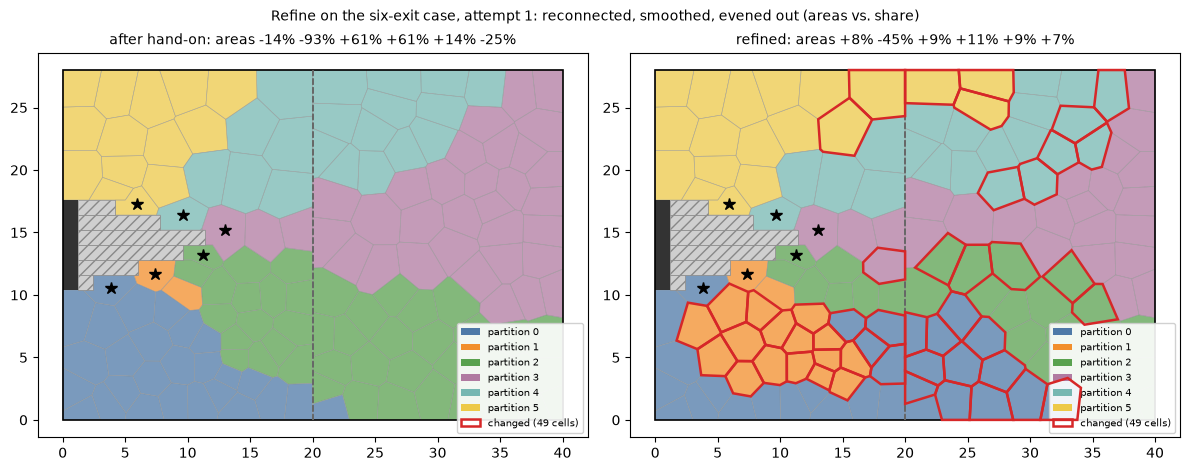

matches the recording: True


In [25]:
def before_after(cut, g, b, a_, titles, k_count, zoom=None, title=None):
    changed = np.nonzero(b != a_)[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, o, t in zip(axes, (b, a_), titles):
        owners(ax, cut.arr, o)
        base(ax, g, cut.lanes, t)
        fronts(ax, cut.arr, cut.front)
        if zoom:
            ax.set_xlim(*zoom[0])
            ax.set_ylim(*zoom[1])
    mark(axes[1], cut.arr, changed)
    for ax in axes:
        legend(ax, [("patch", PALETTE[k], f"partition {k}") for k in range(k_count)]
               + [("edge", CHANGED, f"changed ({len(changed)} cells)")], loc="lower right")
    if title:
        plt.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


def offs(cut, o):
    have = np.bincount(o, cut.area, len(cut.front))
    return " ".join(f"{e:+.0%}" for e in have / cut.want - 1)


a["refined"] = _refine(a["grown"], cut.nbrs, cut.zone, cut.area, cut.want, cut.front)
before_after(cut, g, a["grown"], a["refined"],
             [f"after hand-on: areas {offs(cut, a['grown'])}",
              f"refined: areas {offs(cut, a['refined'])}"], 6,
             title="Refine on the six-exit case, attempt 1: reconnected, smoothed, evened out (areas vs. share)")
print("matches the recording:", all(a[k].tolist() == c["attempts"][0][k] for k in ("weighted", "grown", "refined")))

### 3.10 Widen necks

For each partition, first as a whole and then per panel, while it has two or more wide parts (`_Necks.parts`), `_widened` repeats:

1. `_cheapest`: a 0–1 shortest path from the largest wide part to the next. The partition's own cells are free, other cells cost 1, and front cells of others are forbidden.
2. Collect the cells to take: the foreign cells on that path, plus (`_Necks.narrow`) the neighbours' cells on the far side of any border that keeps a probe along the path from being clear. A fold is never "fixed".
3. Take each of these cells only if its owner can spare it: the owner stays connected through `nbrs` (as `_refine` will require), and `_Necks.spares` holds. `spares` checks that, within 3 steps of the cell, the owner's clear groups do not split into more pieces. Taking a cell must not create a new neck elsewhere.

This stops when the partition is one wide part, nothing can be taken, or after `WIDEN` rounds. Necks that cannot be widened remain and count against the attempt in 3.12.

In [26]:
def _widened(
    owner: np.ndarray,
    necks: _Necks,
    nbrs: list[list[tuple[int, float]]],
    fixed: set[int],
) -> np.ndarray:
    """Each partition's necks widened where the cells beside allow, as a whole and zone by
    zone (a curve's regions are a partition's pieces in each zone, each laid out on its own,
    joined to the others across the folds): where its wide parts (``_Necks``) are several,
    it takes the cells on the cheapest way from its largest to the next (its own cells free,
    a neighbour's at a cost) and those of the neighbours' that keep the way narrow, each a
    neighbour can spare (not one it needs to hold together itself or to stay wide, nor a
    strip's end's), until its wide parts are one or none can be spared. (Of a piece through
    walls a port long, ``nbrs``, as ``_refine`` keeps partitions: a piece joined to the rest
    by a shorter wall only, it hands on whole.)"""
    owner = owner.copy()
    nb, zn = necks.nb, necks.zn
    for _ in range(3):
        moved = False
        for k in range(int(owner.max()) + 1):
            for z in [None, *sorted(set(zn[owner == k].tolist()))]:
                for _ in range(WIDEN):
                    parts = necks.parts(owner, k, z)
                    if len(parts) < 2:
                        break
                    path = _cheapest(owner, nb, zn, k, z, parts[0], set(parts[1]), fixed)
                    if path is None:
                        break
                    took = False
                    want = [c for c in path if owner[c] != k]
                    want += necks.narrow(owner, [c for c in path if owner[c] == k], z)
                    for j in dict.fromkeys(want):
                        if (
                            j not in fixed
                            and _connected(owner, nbrs, int(owner[j]), j)
                            and necks.spares(owner, j)
                        ):
                            owner[j] = k
                            took = moved = True
                    if not took:
                        break
        if not moved:
            break
    return owner


def _cheapest(
    owner: np.ndarray,
    nb: list[list[int]],
    zn: np.ndarray,
    k: int,
    z: int | None,
    start: list[int],
    goal: set[int],
    fixed: set[int],
) -> list[int] | None:
    """The cheapest way through the cells (in zone ``z``; None: any) from ``start`` to
    ``goal``: partition ``k``'s cells free, any other's one each (a strip's end's: none)."""
    dist = {c: 0 for c in start}
    back: dict[int, int] = {}
    heap = [(0, c) for c in start]
    while heap:
        d, c = heapq.heappop(heap)
        if c in goal:
            path = [c]
            while path[-1] in back:
                path.append(back[path[-1]])
            return path
        if d > dist[c]:
            continue
        for j in nb[c]:
            if (z is not None and zn[j] != z) or (j in fixed and owner[j] != k):
                continue
            nd = d + (0 if owner[j] == k else 1)
            if nd < dist.get(j, math.inf):
                dist[j] = nd
                back[j] = c
                heapq.heappush(heap, (nd, j))
    return None

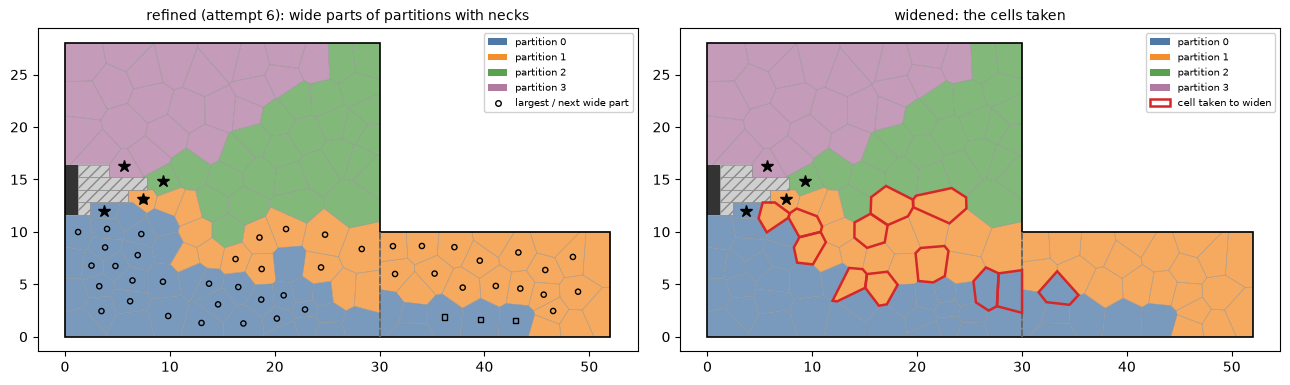

necks (partitions or panel pieces with ≥2 wide parts) before: 3  after widening: 0


In [27]:
cut, tries = run_attempts("necks")
g = GEOM["necks"]
best = max(range(len(tries)), key=lambda i: (tries[i]["refined"] != tries[i]["widened"]).sum())
t = tries[best]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, o, title in [(axes[0], t["refined"], f"refined (attempt {best + 1}): wide parts of partitions with necks"),
                     (axes[1], t["widened"], "widened: the cells taken")]:
    owners(ax, cut.arr, o)
    base(ax, g, cut.lanes, title)
    fronts(ax, cut.arr, cut.front)
o = t["refined"]
x, y = cut.cen.T
for k in range(int(o.max()) + 1):
    for z in [None, *sorted(set(cut.necks.zn[o == k].tolist()))]:
        parts = cut.necks.parts(o, k, z)
        if len(parts) > 1:
            for part, m in zip(parts[:2], ("o", "s")):
                axes[0].scatter(x[part], y[part], marker=m, s=14, facecolors="none", edgecolors="black", zorder=8)
mark(axes[1], cut.arr, np.nonzero(t["refined"] != t["widened"])[0])
legend(axes[0], [("patch", PALETTE[k], f"partition {k}") for k in range(4)]
       + [("hollow", "black", "largest / next wide part")], loc="upper right")
legend(axes[1], [("patch", PALETTE[k], f"partition {k}") for k in range(4)]
       + [("edge", CHANGED, "cell taken to widen")], loc="upper right")
plt.tight_layout()
plt.show()
print("necks (partitions or panel pieces with ≥2 wide parts) before:", cut.necks.left(t["refined"]),
      " after widening:", cut.necks.left(t["widened"]))

### 3.11 Guarded refine

Widening takes area from neighbours, so the areas are evened out again by the same `_refine`, now with `guard = necks.spares`: no balancing move may narrow the giver into a new neck. The result, and how many necks remain (`_Necks.left`), is the attempt's result.

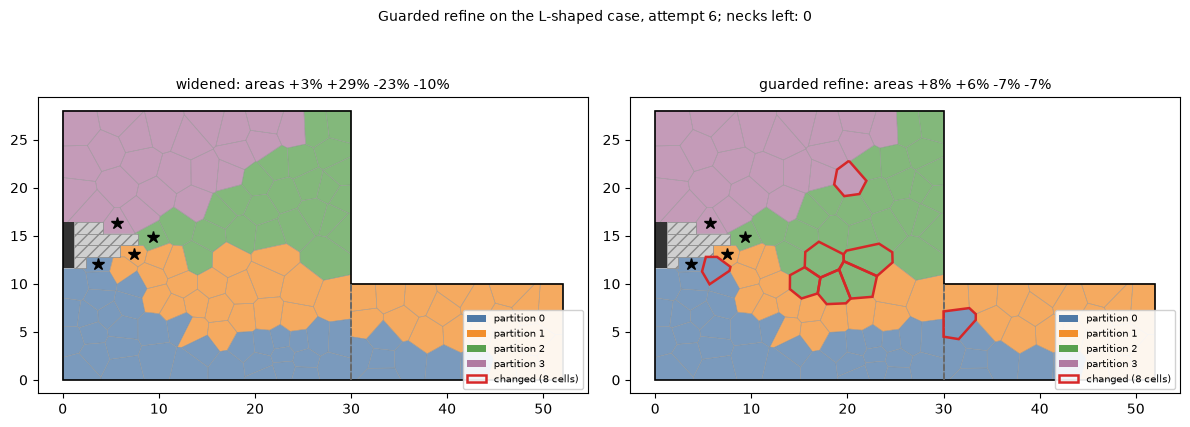

In [28]:
before_after(cut, g, t["widened"], t["balanced"],
             [f"widened: areas {offs(cut, t['widened'])}", f"guarded refine: areas {offs(cut, t['balanced'])}"], 4,
             title=f"Guarded refine on the L-shaped case, attempt {best + 1}; necks left: {t['necks']}")

### 3.12 Choosing an attempt

`partition` runs up to `ATTEMPTS` = 6 attempts on the same cells, stopping early at the first with **no neck** and areas within `UNEVEN` = 3 %. Otherwise the attempts are ranked by (less even than 3 %?, number of necks, unevenness): a neck-free attempt wins unless it is lopsided. The best one is finished, provided it is within 50 %. If its port doesn't end up inside its partition (a union grid artefact), the next is tried. If none qualifies, `Uneven` is raised, and the layout retries with a salted seed.

In [29]:
def partition(
    area: shapely.Geometry,
    zones: list[Polygon],
    ports: list[Polygon],
    inward: tuple[float, float],
    width: float,
    seed: int,
) -> list[Partition]:
    """``area`` split into one partition per port (in their order along the junction;
    ``inward`` the way from the junction into the area), of equal area, each holding its
    port, ``width`` wide (a pair of trace lanes: the ports' width), and its strip. A split
    that comes out uneven is tried again afresh."""
    rng = Rand.of(seed, "partition")
    cut = _Cells(area, zones, ports, inward, width, rng)
    tried = []
    for _ in range(ATTEMPTS):
        owner, necks = cut.attempt(rng)
        have = np.bincount(owner, cut.area, len(ports)) + cut.held
        off = float((have.max() - have.min()) / have.max())
        tried.append(((off > LOPSIDED, necks, off), len(tried), owner))
        if not necks and off < UNEVEN:
            break
    for (_, _, off), _, owner in sorted(tried, key=lambda t: t[:2]):
        if off > 0.5:
            break
        parts = cut.finished(owner)
        # (each port in its partition: but the slivers snapping to the union's grid leaves)
        if all(p.port.difference(p.area).area <= 1e-6 * max(1.0, p.port.area) for p in parts):
            return parts
    raise Uneven("could not split the mesh's area into partitions")

In [30]:
print(f"{'case':>14}  attempts: (necks left, unevenness)   → chosen")
for name, c in CASES.items():
    s = "  ".join(f"({a['necks']},{a['off']:4.0%})" for a in c["attempts"])
    ch = "error: " + c["error"] if c["error"] else f"attempt {c['chosen'] + 1}"
    print(f"{name:>14}  {s}   → {ch}")

          case  attempts: (necks left, unevenness)   → chosen
       typical  (1,  2%)  (0,  1%)   → attempt 2
        single  (0,  0%)   → attempt 1
           six  (2, 56%)  (3, 32%)  (3, 23%)  (3, 10%)  (2, 56%)  (2, 10%)   → attempt 6
      dumbbell  (0, 62%)  (0, 62%)  (0, 62%)  (0, 62%)  (0, 62%)  (0, 62%)   → error: could not split the mesh's area into partitions
 fold-at-exits  (0,  1%)   → attempt 1
         necks  (0, 22%)  (0, 22%)  (2,  4%)  (3,  3%)  (3,  2%)  (0, 14%)   → attempt 5


### 3.13 Pinched

After the choice, `_pinched` looks at each partition's piece in each panel as geometry: it shrinks the piece by a quarter port (the curve keeps half a spacing off borders). If the piece comes apart, the cells past the gap (those not covered by the largest remaining part) go to the neighbour beside them most, because no curve would reach them. None of the six recorded cases triggers it (the neck widening usually prevents such passages), so here it is shown on a constructed split: a partition reaching into a neighbour through a single sliver cell.

In [31]:
def _pinched(
    owner: np.ndarray,
    arr: np.ndarray,
    zone: list[int],
    loose: list[list[tuple[int, float]]],
    front: list[int],
    width: float,
) -> np.ndarray:
    """The cells of a partition's piece in a zone past a passage narrower than its curve's
    run in and back out (where its curve's domain, the piece shrunk by half a spacing, comes
    apart: what lies past it no curve reaches) to the neighbour beside them most."""
    owner = owner.copy()
    zn = np.asarray(zone)
    cen = shapely.points(shapely.get_coordinates(shapely.centroid(arr)))
    fixed = set(front)
    for _ in range(4):
        moved = False
        for k in range(owner.max() + 1):
            for z in set(zn[owner == k].tolist()):
                mine = np.nonzero((owner == k) & (zn == z))[0]
                piece = shapely.union_all(arr[mine], grid_size=1e-6)
                for g in _parts(piece):
                    parts = _parts(g.buffer(-width / 4))
                    if len(parts) < 2:
                        continue
                    main = max(parts, key=lambda q: q.area).buffer(width / 4 + 1e-6)
                    for i in mine:
                        if i in fixed or not g.covers(cen[i]) or main.covers(cen[i]):
                            continue
                        near = [owner[j] for j, _ in loose[i] if owner[j] != k]
                        if near:
                            owner[i] = max(set(near), key=near.count)
                            moved = True
        if not moved:
            break
    return owner

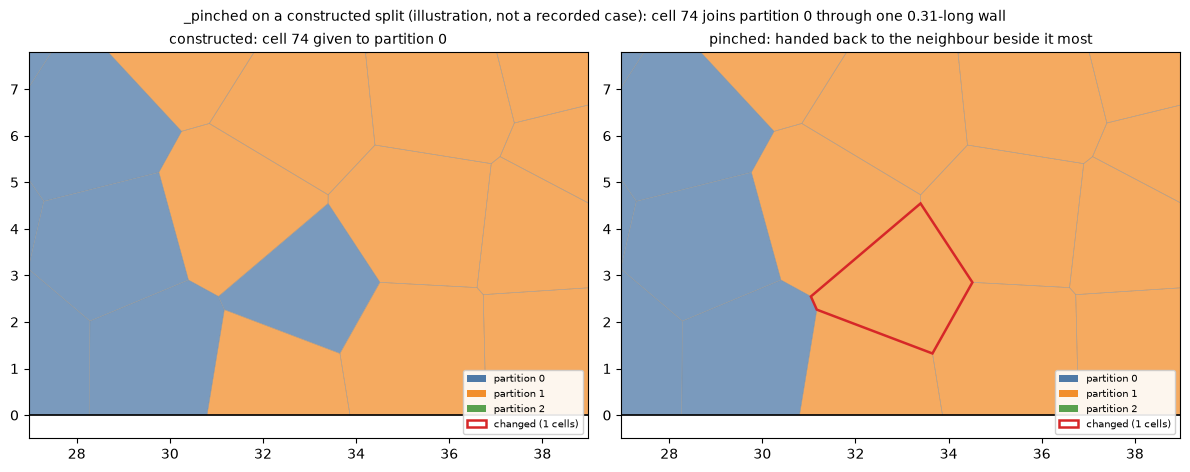

In [32]:
cut, rng = setup("typical")
g = GEOM["typical"]
o = np.array(CASES["typical"]["pinched"])
# Construct a pinch: a cell handed to a partition it touches through one wall shorter than half a
# port only (found by search), so that partition's piece narrows to that wall there
wa, wb, ww = _walls(list(cut.arr))
length = {}
for x_, y_, l_ in zip(wa, wb, shapely.length(ww)):
    length[(x_, y_)] = length[(y_, x_)] = l_


def pinch_candidate():
    for j in range(len(o)):
        if j in cut.front:
            continue
        for k in range(int(o.max()) + 1):
            touching = [q for q, _ in cut.loose[j] if o[q] == k]
            if k == o[j] or len(touching) != 1 or length[(j, touching[0])] >= g["width"] / 2:
                continue
            trial = o.copy()
            trial[j] = k
            if (_pinched(trial, cut.arr, cut.zone, cut.loose, cut.front, cut.width) != trial).any():
                return j, k, length[(j, touching[0])]


j, k_to, wall = pinch_candidate()
o2 = o.copy()
o2[j] = k_to
after = _pinched(o2, cut.arr, cut.zone, cut.loose, cut.front, cut.width)
cx, cy = cut.cen[j]
before_after(cut, g, o2, after, [f"constructed: cell {j} given to partition {k_to}",
                                 "pinched: handed back to the neighbour beside it most"], 3,
             zoom=((cx - 6, cx + 6), (max(cy - 5, -0.5), cy + 5)),
             title=f"_pinched on a constructed split (illustration, not a recorded case): cell {j} "
                   f"joins partition {k_to} through one {wall:.2f}-long wall")

### 3.14 Finish

Each partition becomes the union of its cells, its port and its strip (on a 1e-6 grid, to absorb slivers between cells), keeping the piece that reaches the port (`_one`). Its `reach` is how far the strip end lies from the port's outer side, which is where the curve opens. The result is `Partition(area, port, reach)` (the class at the top of section 3).

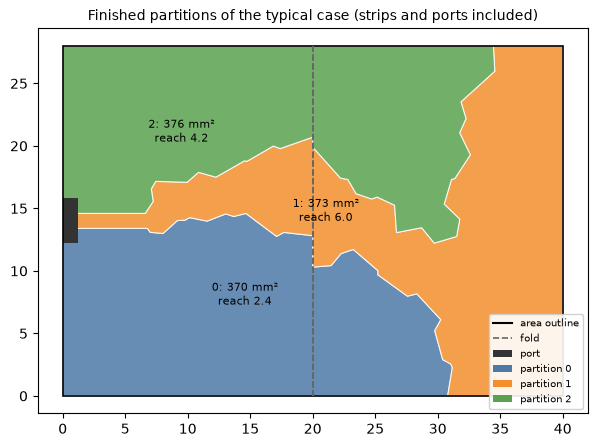

In [33]:
def show_final(ax, name, parts, title):
    g = GEOM[name]
    for k, p in enumerate(parts):
        fill(ax, p.area, facecolor=PALETTE[k], edgecolor="white", lw=0.8, alpha=0.85, zorder=2)
    base(ax, g, None, title)


g = GEOM["typical"]
parts = partition(g["area"], g["zones"], g["ports"], g["inward"], g["width"], g["seed"])
fig, ax = plt.subplots(figsize=(9, 5))
show_final(ax, "typical", parts, "Finished partitions of the typical case (strips and ports included)")
for k, p in enumerate(parts):
    c = p.area.representative_point()
    ax.text(c.x, c.y, f"{k}: {p.area.area:.0f} mm²\nreach {p.reach:.1f}", ha="center", fontsize=8, zorder=9)
legend(ax, BASE_LEGEND[:3] + [("patch", PALETTE[k], f"partition {k}") for k in range(3)], loc="lower right")
plt.show()

## 4. End to end, and verification

The port runs on every case and is compared with the recording, with tolerance `1e-9` for floats and geometry:

- **setup**: strips, Voronoi cells as made, cells after the end boxes (zones, fronts), walls, both graphs, cell areas, shares, probe points and their outline flags;
- **every attempt**: every intermediate split (`weighted`, `grown`, `refined`, `widened`, `balanced`), necks left, unevenness;
- **result**: the chosen attempt, `_pinched`'s split, and the output polygons, ports and reaches. These come from the faithful `partition()`, not from the recording helpers. The case that cannot be split must raise the same error.

In [34]:
TOL = 1e-9


def same_geoms(a, b):
    return len(a) == len(b) and all(shapely.from_wkt(y).equals_exact(x, TOL) or
                                    shapely.from_wkt(y).symmetric_difference(x).area < TOL
                                    for x, y in zip(a, b))


def verify(name):
    c, g = CASES[name], GEOM[name]
    rec, res = c["setup"], {}
    cut, rng = setup(name)
    res["strips"] = same_geoms(cut.lanes, rec["lanes"])
    rng2 = Rand.of(g["seed"], "partition")
    v_polys, v_zone, v_front = cells(shapely.difference(g["area"], shapely.union_all([*g["ports"], *cut.lanes])),
                                     g["zones"], CELL * g["width"], rng2,
                                     [tuple(e) for e in rec["ends"]])
    res["voronoi cells"] = (same_geoms(v_polys, rec["voronoi"]["cells"]) and v_zone == rec["voronoi"]["zone"]
                            and v_front == rec["voronoi"]["front"])
    res["cells"] = (same_geoms(list(cut.arr), rec["cells"]["cells"]) and cut.zone == rec["cells"]["zone"]
                    and cut.front == rec["cells"]["front"])
    a, b, w = _walls(list(cut.arr))
    res["walls"] = (a.tolist() == rec["walls"]["a"] and b.tolist() == rec["walls"]["b"]
                    and np.allclose(shapely.length(w), rec["walls"]["length"], atol=TOL))
    res["graphs"] = ([[j for j, _ in v] for v in cut.nbrs] == rec["nbrs"]
                     and [[j for j, _ in v] for v in cut.loose] == rec["loose"])
    res["areas, shares"] = all(np.allclose(getattr(cut, k), rec[k], atol=TOL) for k in ("area", "held", "want"))
    res["probes"] = (np.allclose(shapely.get_coordinates(cut.necks.probes), rec["probes"]["xy"], atol=TOL)
                     and cut.necks.always.tolist() == rec["probes"]["always"])
    tries = [attempt_stages(cut, rng) for _ in c["attempts"]]
    res["attempts"] = all(
        all(t[k].tolist() == r[k] for k in ("weighted", "grown", "refined", "widened", "balanced"))
        and t["necks"] == r["necks"] and abs(t["off"] - r["off"]) < TOL
        for t, r in zip(tries, c["attempts"]))
    if c["chosen"] is not None:
        res["chosen, pinched"] = (tries[c["chosen"]]["balanced"].tolist() == c["attempts"][c["chosen"]]["balanced"]
                                  and _pinched(tries[c["chosen"]]["balanced"], cut.arr, cut.zone, cut.loose,
                                               cut.front, cut.width).tolist() == c["pinched"])
    try:
        parts = partition(g["area"], g["zones"], g["ports"], g["inward"], g["width"], g["seed"])
        err = None
    except MeshError as e:
        parts, err = [], str(e)
    res["output"] = (err == c["error"]
                     and same_geoms([p.area for p in parts], [o["area"] for o in c["output"]])
                     and same_geoms([p.port for p in parts], [o["port"] for o in c["output"]])
                     and np.allclose([p.reach for p in parts], [o["reach"] for o in c["output"]], atol=TOL))
    return res, parts, err


results = {}
t0 = time.perf_counter()
for name in CASES:
    results[name] = verify(name)
print(f"verified {len(results)} cases in {time.perf_counter() - t0:.1f} s\n")
keys = list(next(iter(results.values()))[0])
print(f"{'case':>14}  " + "  ".join(f"{k:>15}" for k in keys))
for name, (res, _, _) in results.items():
    print(f"{name:>14}  " + "  ".join(f"{('ok' if res.get(k, True) else 'MISMATCH') if k in res else '-':>15}"
                                       for k in keys))
assert all(all(r.values()) for r, _, _ in results.values()), "the port does not match the recording"
print("\nall checks pass")

verified 6 cases in 1.7 s

          case           strips    voronoi cells            cells            walls           graphs    areas, shares           probes         attempts  chosen, pinched           output
       typical               ok               ok               ok               ok               ok               ok               ok               ok               ok               ok
        single               ok               ok               ok               ok               ok               ok               ok               ok               ok               ok
           six               ok               ok               ok               ok               ok               ok               ok               ok               ok               ok
      dumbbell               ok               ok               ok               ok               ok               ok               ok               ok                -               ok
 fold-at-exits               ok               ok

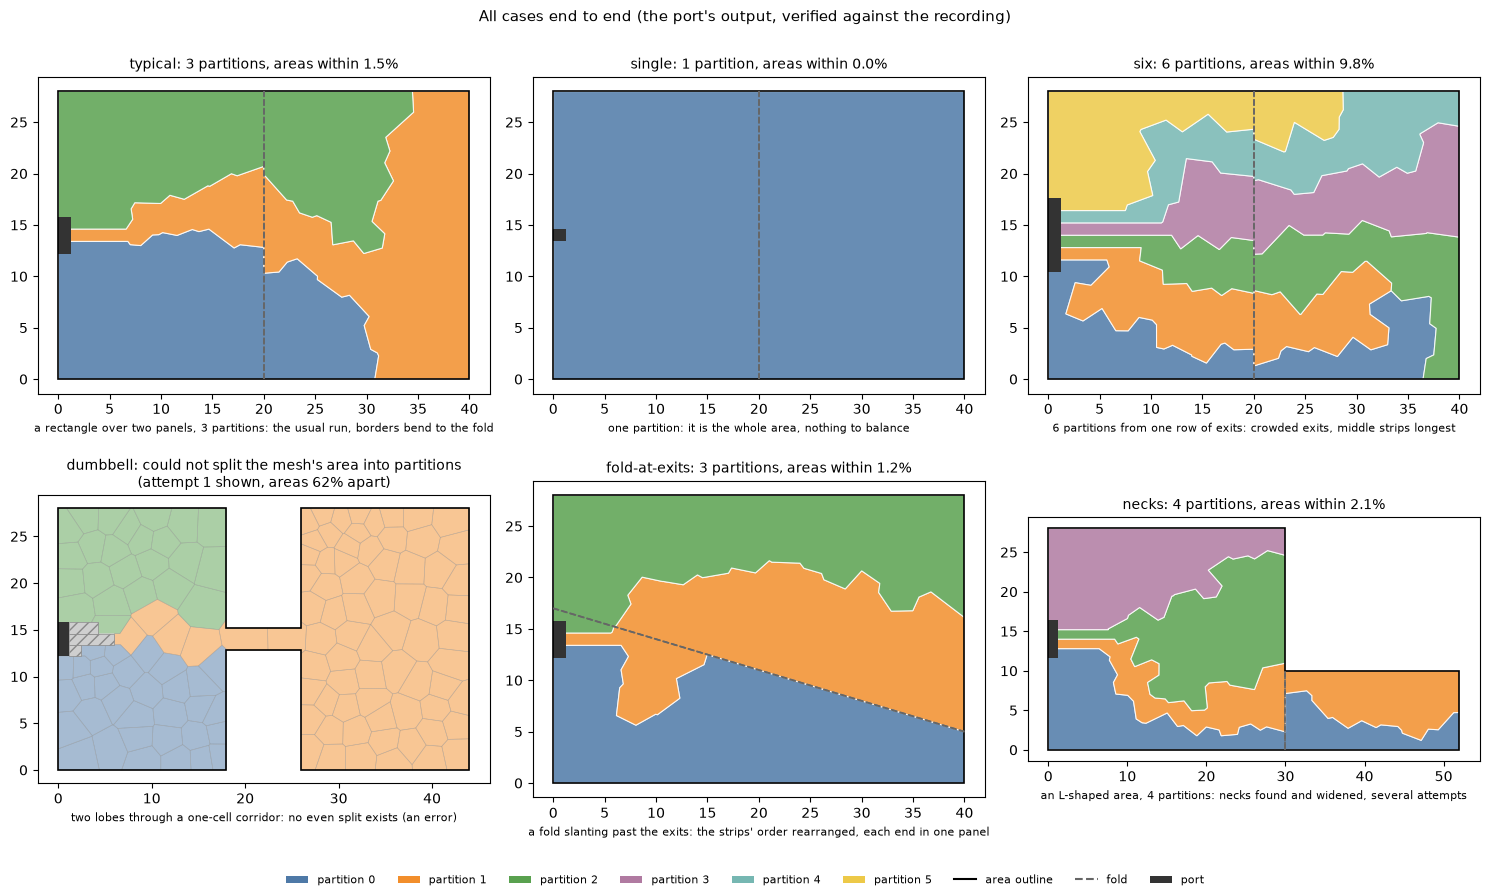

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, (_, parts, err)) in zip(axes.ravel(), results.items()):
    c = CASES[name]
    if parts:
        a = [p.area.area for p in parts]
        n = len(parts)
        show_final(ax, name, parts, f"{name}: {n} partition{'s' if n > 1 else ''}, areas within {(max(a) - min(a)) / max(a):.1%}")
    else:
        cut, _ = setup(name)
        best_try = c["attempts"][0]
        owners(ax, cut.arr, np.array(best_try["balanced"]), alpha=0.5)
        base(ax, GEOM[name], cut.lanes, f"{name}: {err}\n(attempt 1 shown, areas {best_try['off']:.0%} apart)")
    ax.set_xlabel(c["note"], fontsize=8)
handles = [Patch(facecolor=PALETTE[k], label=f"partition {k}") for k in range(6)] + [
    Line2D([], [], color="black", label="area outline"), Line2D([], [], color=FOLD_C, ls="--", label="fold"),
    Patch(facecolor=PORT_C, label="port")]
fig.legend(handles=handles, loc="lower center", ncol=9, fontsize=8, frameon=False)
plt.suptitle("All cases end to end (the port's output, verified against the recording)", fontsize=11)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

What the grid shows:

- **typical**, **single** and **fold-at-exits** split cleanly. With a fold near the exits the strips are reordered, and borders follow the fold where they can.
- **six**: six exits crowded into a small area. Every attempt keeps a neck or is uneven; the best is about 10 % uneven. Small areas with many partitions are this method's weak spot (see below).
- **dumbbell**: no even split exists. The corridor is one cell wide, so only one partition can pass through it, and the lobe behind it is larger than one share. `Uneven` is raised, which in the layout triggers a salted retry and finally an error message.
- **necks**: the L-shaped area with a flap needs necks widened in most attempts; the chosen attempt still has some (no neck-free attempt was even enough).

## 5. Closing notes

**Complexity** (`n` cells, about area / (2.5 ports)²; a full board at the real pitch has about 3000–4000 per layer):

| step | cost |
|---|---|
| cells (Voronoi + 3 Lloyd rounds) | O(n log n) in GEOS |
| walls, graphs, probes | O(n log n): R-tree queries; about 10 probes and some 50 probe–wall pairs per cell |
| weighted growth | ≤ 60 Dijkstra runs: O(60 · n log n), in Python (about 0.4 s per attempt at 3500 cells) |
| refine | O(n) per pass; each move's connectivity check is local first (`HOPS`), worst case O(n) |
| neck test (`left`, `parts`) | O(probe–wall pairs) vectorized, plus label propagation with pointer jumping |
| widening | per neck, a 0–1 Dijkstra plus local `spares` checks (cached 3-step windows) |
| whole call | setup about 1 s plus about 1 s per attempt at full size (≤ 6 attempts) |

**Known limitations**

- *Weighted growth doesn't balance.* With all sources clustered at the junction, areas are a discontinuous function of the weights (whole lobes switch owner), so balance comes from local refining, which can leave ragged borders. A harmonic ("angle") field or lockstep growth were tried as replacements and did not do better on the real board.
- *Necks are a proxy.* The test approximates erosion at sample points; the curve stage is the real judge. So the layout (`pcb._partitioned`) runs the curve's graph right after partitioning and, if any region is left bare, re-partitions with a salted seed (`mesh_seed-1`, `-2`, …, up to 8 times) before the expensive relaxation (also when the curve's graph cannot be built at all). In a survey of 800 layers of a 5-partition board, 5 needed a second try and none a third.
- *Small areas with many partitions* (the `six` case) often end with a neck or a 5–10 % imbalance: there are too few cells for the moves to work with.
- *A lobe behind a one-cell passage* that is bigger than a share cannot be split evenly (`dumbbell`); this is reported as an error rather than solved.
- Probes near the outline are never clear, so a partition running along a narrow flap counts as narrow there; that is why natural necks (`_native`) are excluded from the count.

**Where each step lives** (`src/yanartas_pillowbox/partition.py`):

| step | code |
|---|---|
| entry, attempt loop, choice | `partition` |
| 3.1 strips | `strips` |
| 3.2 cells | `cells`, `_voronoi` |
| 3.3 end boxes, setup | `_Cells.__init__` |
| 3.4 walls, graphs | `_walls`, `_graph`, `_connected` |
| 3.5 neck probes, wide parts | `_Necks`, `_components` |
| 3.6–3.8 cost field, growth, hand-on | `_field`, `_weighted`, `_Cells.attempt` |
| 3.9 / 3.11 refine | `_refine` (guard: `_Necks.spares`) |
| 3.10 widening | `_widened`, `_cheapest`, `_Necks.parts`, `_Necks.narrow` |
| 3.13 pinched | `_pinched` |
| 3.14 finish | `_Cells.finished`, `_one` |
| salted retry of a layer | `pcb._partitioned`, `sfc.generate(strict=True)` |

The design rationale is also in `ARCHITECTURE.md` ("Partitions"), and the tests are in `tests/test_partition.py`.